# 1. Loading the Data (20%)

The supplied `data/raw.sql` was imported into `marketplace.sqlite` with `python3 setup_db.py` (8 tables, 116,981 rows). The notebook reads from that database rather than from the raw file, so the original SQL stays unchanged.

Goal of this section: assemble **one row per order** efficiently, with evidence that record meanings, relationships, counts and totals are preserved.

In [1]:
# !pip install xlrd rapidfuzz

In [2]:
import sqlite3
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 50)

DB_PATH = Path.cwd() / "marketplace.sqlite"
connection = sqlite3.connect(DB_PATH)

def query(sql_statement):
    """Run a result-producing SQL statement and return a pandas DataFrame."""
    return pd.read_sql_query(sql_statement, connection)

def execute(sql_statement):
    """Run one or more statements that change the database and commit them."""
    with connection:
        connection.executescript(sql_statement)

In [3]:
import os

db_size_mb = os.path.getsize(DB_PATH) / 1e6

table_names = [
    "orders", "customers", "order_items", "order_payments",
    "order_reviews", "products", "sellers", "category_translation",
]
table_rows = {t: int(query(f"SELECT COUNT(*) AS n FROM {t}")["n"][0]) for t in table_names}
display(pd.Series(table_rows, name="rows").to_frame())

# --- primary-key uniqueness (0 = no duplicates) ---
pk_checks = {
    "orders.order_id": table_rows["orders"] - int(query("SELECT COUNT(DISTINCT order_id) AS n FROM orders")["n"][0]),
    "customers.customer_id": table_rows["customers"] - int(query("SELECT COUNT(DISTINCT customer_id) AS n FROM customers")["n"][0]),
    "products.product_id": table_rows["products"] - int(query("SELECT COUNT(DISTINCT product_id) AS n FROM products")["n"][0]),
    "sellers.seller_id": table_rows["sellers"] - int(query("SELECT COUNT(DISTINCT seller_id) AS n FROM sellers")["n"][0]),
    "order_reviews.review_id": table_rows["order_reviews"] - int(query("SELECT COUNT(DISTINCT review_id) AS n FROM order_reviews")["n"][0]),
    "order_items (order_id, order_item_id)": table_rows["order_items"] - int(query("SELECT COUNT(*) AS n FROM (SELECT DISTINCT order_id, order_item_id FROM order_items)")["n"][0]),
    "order_payments (order_id, payment_sequential)": table_rows["order_payments"] - int(query("SELECT COUNT(*) AS n FROM (SELECT DISTINCT order_id, payment_sequential FROM order_payments)")["n"][0]),
}
display(pd.Series(pk_checks, name="duplicate keys").to_frame())

# --- referential integrity (0 = no orphan rows) ---
fk_results = {
    "order_items -> orders": int(query("SELECT COUNT(*) AS n FROM order_items i LEFT JOIN orders o ON i.order_id = o.order_id WHERE o.order_id IS NULL")["n"][0]),
    "order_payments -> orders": int(query("SELECT COUNT(*) AS n FROM order_payments p LEFT JOIN orders o ON p.order_id = o.order_id WHERE o.order_id IS NULL")["n"][0]),
    "order_reviews -> orders": int(query("SELECT COUNT(*) AS n FROM order_reviews r LEFT JOIN orders o ON r.order_id = o.order_id WHERE o.order_id IS NULL")["n"][0]),
    "orders -> customers": int(query("SELECT COUNT(*) AS n FROM orders o LEFT JOIN customers c ON o.customer_id = c.customer_id WHERE c.customer_id IS NULL")["n"][0]),
    "order_items -> products": int(query("SELECT COUNT(*) AS n FROM order_items i LEFT JOIN products p ON i.product_id = p.product_id WHERE p.product_id IS NULL")["n"][0]),
    "order_items -> sellers": int(query("SELECT COUNT(*) AS n FROM order_items i LEFT JOIN sellers s ON i.seller_id = s.seller_id WHERE s.seller_id IS NULL")["n"][0]),
}
display(pd.Series(fk_results, name="orphan rows").to_frame())

print(f"database file: {db_size_mb:.1f} MB")

,rows
orders,20000
customers,20000
order_items,22662
order_payments,20875
order_reviews,19966
products,11334
sellers,2071
category_translation,73


,duplicate keys
orders.order_id,0
customers.customer_id,0
products.product_id,0
sellers.seller_id,0
order_reviews.review_id,25
"order_items (order_id, order_item_id)",0
"order_payments (order_id, payment_sequential)",0


,orphan rows
order_items -> orders,0
order_payments -> orders,0
order_reviews -> orders,0
orders -> customers,769
order_items -> products,910
order_items -> sellers,893


database file: 24.4 MB


### 1.1 Tables and keys

`orders` is the fact table — one row per order, keyed by `order_id`. Every other table attaches to it directly or through a dimension table:

| table | grain | keys / relationship |
|---|---|---|
| `orders` | 1 row per order | PK `order_id`; `customer_id` → `customers` |
| `customers` | 1 row per order–address pair | PK `customer_id`; `customer_unique_id` ties the same person across orders |
| `order_items` | 1 row per purchased item | FK `order_id`; (`order_id`, `order_item_id`) gives the item's sequence within the order; → `product_id`, `seller_id` |
| `order_payments` | 1 row per payment record | FK `order_id`; `payment_sequential` numbers split payments — an order can have several (Appendix B) |
| `order_reviews` | 1 row per review | PK `review_id`; FK `order_id` — an order can collect more than one review |
| `products` | 1 row per product | PK `product_id` |
| `sellers` | 1 row per seller | PK `seller_id` |
| `category_translation` | lookup | `product_category_name` → English name |

The one-to-many children (`order_items`, `order_payments`, `order_reviews`) would multiply order rows if joined naively. Each is therefore **aggregated to order grain first**, then merged left onto `orders`, so the assembled table keeps exactly one row per order. The checks after every merge below prove it.

In [4]:
order_df = query("""--sql
SELECT * from orders
""")

display(order_df.head())
display(order_df.info())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,None,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06 00:00:00
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11 00:00:00
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       20000 non-null  object
 1   customer_id                    20000 non-null  object
 2   order_status                   20000 non-null  object
 3   order_purchase_timestamp       19832 non-null  object
 4   order_approved_at              19801 non-null  object
 5   order_delivered_carrier_date   19517 non-null  object
 6   order_delivered_customer_date  19286 non-null  object
 7   order_estimated_delivery_date  19840 non-null  object
dtypes: object(8)
memory usage: 1.2+ MB


None

In [5]:
# convert to pd datetime
order_df['order_purchase_timestamp'] = pd.to_datetime(order_df['order_purchase_timestamp'], errors='coerce')
order_df['order_approved_at'] = pd.to_datetime(order_df['order_approved_at'], errors='coerce')
order_df['order_delivered_carrier_date'] = pd.to_datetime(order_df['order_delivered_carrier_date'], errors='coerce')
order_df['order_delivered_customer_date'] = pd.to_datetime(order_df['order_delivered_customer_date'], errors='coerce')
order_df['order_estimated_delivery_date'] = pd.to_datetime(order_df['order_estimated_delivery_date'], errors='coerce')

order_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       20000 non-null  object        
 1   customer_id                    20000 non-null  object        
 2   order_status                   20000 non-null  object        
 3   order_purchase_timestamp       19667 non-null  datetime64[ns]
 4   order_approved_at              19649 non-null  datetime64[ns]
 5   order_delivered_carrier_date   19368 non-null  datetime64[ns]
 6   order_delivered_customer_date  19125 non-null  datetime64[ns]
 7   order_estimated_delivery_date  19670 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 1.2+ MB


## add reviews

In [6]:
# we try to map the duplicate review with a nearest null review
review_df = query("""--sql
SELECT * from order_reviews
""")

display(review_df.head())
display(review_df.info())


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4.0,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22T00:00:00,2018-02-30T10:00:00
1,4b49719c8a200003f700d3d986ea1a19,9d6f15f95d01e79bd1349cc208361f09,4.0,None,"Mas um pouco ,travando...pelo valor ta Boa.\n",2018-02-16T00:00:00,2018-02-20T10:52:22
2,23f75a37effc35d9a915b4e1ad483793,2eaf8e099d871cd5c22b83b5ea8f6e0e,4.0,None,None,2018-03-28T00:00:00,2018-03-30T15:10:55
3,fdbdb2629a7cde0f66657acc92084e7f,70a752414a13d09cc1f2b437b914b28e,3.0,None,None,2017-09-29T00:00:00,2017-10-02T01:12:49
4,a2ff510ca4e059c3fefc7a7866571f6f,a9953b2f0b1665ac7586cc5a6ac8f58c,4.0,None,None,None,2017-10-08T22:36:05


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19966 entries, 0 to 19965
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   review_id                19966 non-null  object 
 1   order_id                 19966 non-null  object 
 2   review_score             18894 non-null  float64
 3   review_comment_title     2313 non-null   object 
 4   review_comment_message   8184 non-null   object 
 5   review_creation_date     19376 non-null  object 
 6   review_answer_timestamp  19404 non-null  object 
dtypes: float64(1), object(6)
memory usage: 1.1+ MB


None

In [7]:
review_date_col = ['review_creation_date', 'review_answer_timestamp']
for col in review_date_col:
    review_df[col] = pd.to_datetime(review_df[col], errors='coerce')

display(review_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19966 entries, 0 to 19965
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                19966 non-null  object        
 1   order_id                 19966 non-null  object        
 2   review_score             18894 non-null  float64       
 3   review_comment_title     2313 non-null   object        
 4   review_comment_message   8184 non-null   object        
 5   review_creation_date     18842 non-null  datetime64[ns]
 6   review_answer_timestamp  18913 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(1), object(4)
memory usage: 1.1+ MB


/var/folders/nm/b_657b8s0_n7nkw6gl0z9shw0000gq/T/ipykernel_48965/812412330.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  review_df[col] = pd.to_datetime(review_df[col], errors='coerce')


None

In [8]:
# review duplicate order_id first
print(f"duplicate order_id: {review_df['order_id'].duplicated().sum()}")

review_df_nodup = (
    review_df
    .sort_values("review_creation_date")
    .drop_duplicates(subset="order_id", keep="last")
)

# review_df_nodup = review_df[review_df['order_id'].duplicated(keep=False) == False]
review_df_dup = review_df[review_df['order_id'].duplicated(keep=False) == True]
print(f"duplicate order_id after: {review_df_nodup['order_id'].duplicated().sum()}")
review_df_nodup.info()

duplicate order_id: 113
duplicate order_id after: 0
<class 'pandas.core.frame.DataFrame'>
Index: 19853 entries, 12241 to 19943
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                19853 non-null  object        
 1   order_id                 19853 non-null  object        
 2   review_score             18787 non-null  float64       
 3   review_comment_title     2311 non-null   object        
 4   review_comment_message   8147 non-null   object        
 5   review_creation_date     18729 non-null  datetime64[ns]
 6   review_answer_timestamp  18805 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(1), object(4)
memory usage: 1.2+ MB


In [9]:
order_df_v2 = order_df.merge(review_df_nodup, on='order_id', how='left')
order_df_v2

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec396e317ff4c82a03ce16a0c3eb3,delivered,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22,ede62474f1618961be12678f362dca4a,0.0,None,Otimo comprar por este site as mercadorias che...,2017-11-11,2017-11-15 09:54:14
19997,cfa78b997e329a5295b4ee6972c02979,a2f7428f0cafbc8e59f20e1444b67315,DELIVERED,2017-12-20 09:52:41,2017-12-20 10:09:52,2017-12-20 20:25:25,2018-01-26 15:45:14,2018-01-18,8ea780895f362ce949029f95b7181ff0,1.0,None,"Ele não é um mini cajon, é um shaker, ou seja,...",2018-01-19,2018-01-21 02:51:39
19998,9115830be804184b91f5c00f6f49f92d,da2124f134f5dfbce9d06f29bdb6c308,delivered,2017-10-04 19:57:37,2017-10-04 20:07:14,2017-10-05 16:52:52,2017-10-20 20:25:45,2017-11-07,ebd75732b5804e934123d11ec1f11db0,5.0,None,None,2017-10-21,2017-10-23 14:48:40


In [10]:
# Verification: merging the deduplicated reviews must not change the order count
assert len(order_df_v2) == len(order_df), "review merge changed the number of orders!"

review_dup_rows = int(review_df["order_id"].duplicated().sum())
orders_matched_review = int(order_df_v2["review_id"].notna().sum())

print(f"orders: {len(order_df):,} -> {len(order_df_v2):,} (row count preserved)")
print(f"review rows collapsed as duplicates: {review_dup_rows}")
print(f"orders matched to a review: {orders_matched_review:,} / {len(order_df_v2):,}")

orders: 20,000 -> 20,000 (row count preserved)
review rows collapsed as duplicates: 113
orders matched to a review: 19,853 / 20,000


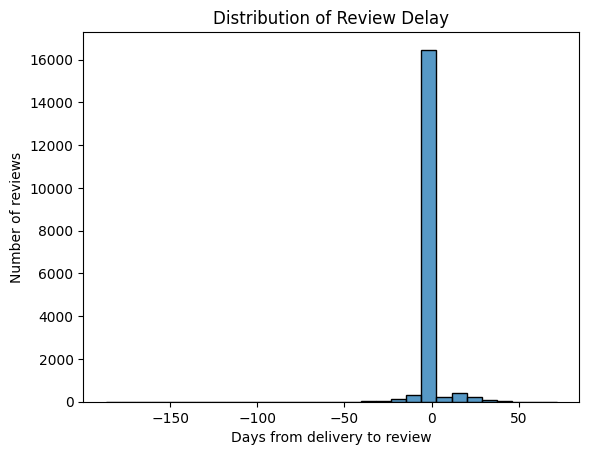

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

days = (
    order_df_v2["review_creation_date"]
    - order_df_v2["order_delivered_customer_date"]
).dt.total_seconds() / (24 * 3600)

sns.histplot(days, bins=30)
plt.xlabel("Days from delivery to review")
plt.ylabel("Number of reviews")
plt.title("Distribution of Review Delay")
plt.show()

## add payments

In [12]:
payment_df = query("""--sql
SELECT * from order_payments
""")
payment_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,-6571.0
1,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,NaN
2,2480f727e869fdeb397244a21b721b67,1,credit_card,1,14190.0
3,8ac09207f415d55acff302df7d6a895c,1,credit_card,4,24415.0
4,8cd68144cdb62dc0d60848cf8616d2a4,1,boleto,1,33066.0


In [13]:
payment_df[payment_df['order_id'].duplicated(keep=False)].sort_values('order_id')
# here we can see that an order has several payment

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19915,002f19a65a2ddd70a090297872e6d64e,2,voucher,1,3318.0
4115,002f19a65a2ddd70a090297872e6d64e,1,voucher,1,4411.0
12056,00b4a910f64f24dbcac04fe54088a443,1,credit_card,1,254.0
2675,00b4a910f64f24dbcac04fe54088a443,2,voucher,1,4805.0
12319,00c95282163553a982f38481f9488481,3,voucher,1,2000.0
...,...,...,...,...,...
3432,fe4021e2697d2b86229336b10e91128c,1,credit_card,1,140.0
12352,ff1f8f328e5a59ac754240b6dd31bcb4,2,voucher,1,7828.0
15337,ff1f8f328e5a59ac754240b6dd31bcb4,3,voucher,1,14258.0
14686,ff1f8f328e5a59ac754240b6dd31bcb4,1,credit_card,1,1117.0


In [14]:
# aggregate payment
payment_summary = (
    payment_df
    .groupby("order_id")
    .agg(
        payment_count=("payment_sequential", "count"),
        total_payment=("payment_value", "sum"),
        max_installments=("payment_installments", "max"),
        payment_types=("payment_type", "nunique"),
    )
    .reset_index()
)

payment_summary

,order_id,payment_count,total_payment,max_installments,payment_types
0,000e562887b1f2006d75e0be9558292e,1,4111.0,4,1
1,000e906b789b55f64edcb1f84030f90d,1,3384.0,3,1
2,0013503b13da1eac686219390b7d641b,1,13722.0,1,1
3,00137e170939bba5a3134e2386413108,1,42165.0,1,1
4,001c85b5f68d2be0cb0797afc9e8ce9a,1,11271.0,4,1
...,...,...,...,...,...
19995,fffb9224b6fc7c43ebb0904318b10b5f,1,35676.0,1,1
19996,fffc94f6ce00a00581880bf54a75a037,1,34340.0,1,1
19997,fffcd46ef2263f404302a634eb57f7eb,1,38653.0,1,1
19998,fffe18544ffabc95dfada21779c9644f,1,6471.0,3,1


In [15]:
order_df_v3 = order_df_v2.merge(payment_summary, on='order_id', how='left')
order_df_v3

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,17912.0,3,1
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,3595.0,1,1
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,2975.0,1,1
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,6334.0,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,19491.0,10,1
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec396e317ff4c82a03ce16a0c3eb3,delivered,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22,ede62474f1618961be12678f362dca4a,0.0,None,Otimo comprar por este site as mercadorias che...,2017-11-11,2017-11-15 09:54:14,1,16430.0,3,1
19997,cfa78b997e329a5295b4ee6972c02979,a2f7428f0cafbc8e59f20e1444b67315,DELIVERED,2017-12-20 09:52:41,2017-12-20 10:09:52,2017-12-20 20:25:25,2018-01-26 15:45:14,2018-01-18,8ea780895f362ce949029f95b7181ff0,1.0,None,"Ele não é um mini cajon, é um shaker, ou seja,...",2018-01-19,2018-01-21 02:51:39,1,7104.0,1,1
19998,9115830be804184b91f5c00f6f49f92d,da2124f134f5dfbce9d06f29bdb6c308,delivered,2017-10-04 19:57:37,2017-10-04 20:07:14,2017-10-05 16:52:52,2017-10-20 20:25:45,2017-11-07,ebd75732b5804e934123d11ec1f11db0,5.0,None,None,2017-10-21,2017-10-23 14:48:40,2,10679.0,2,2


In [16]:
assert len(order_df_v3) == len(order_df), "payment merge changed the number of orders!"

pay_raw_total = float(payment_df["payment_value"].sum())
pay_agg_total = float(order_df_v3["total_payment"].sum())
pay_diff = pay_raw_total - pay_agg_total

print(f"orders: {len(order_df):,} -> {len(order_df_v3):,} (row count preserved)")
print(f"sum(payment_value) raw:  {pay_raw_total:,.2f}")
print(f"sum(total_payment) agg:  {pay_agg_total:,.2f}")
print(f"difference: {pay_diff:.6f}  (totals preserved)")
print(f"orders with no payment row: {int(order_df_v3['payment_count'].isna().sum())}")

orders: 20,000 -> 20,000 (row count preserved)
sum(payment_value) raw:  280,524,473.00
sum(total_payment) agg:  280,524,473.00
difference: 0.000000  (totals preserved)
orders with no payment row: 0


## add items

In [17]:
item_df = query("""--sql
SELECT * from order_items
""")
item_df.head()
item_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22662 entries, 0 to 22661
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             22662 non-null  object 
 1   order_item_id        22662 non-null  int64  
 2   product_id           22662 non-null  object 
 3   seller_id            22662 non-null  object 
 4   shipping_limit_date  21805 non-null  object 
 5   price                22223 non-null  float64
 6   freight_value        22235 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 1.2+ MB


In [18]:
item_df["shipping_limit_date"] = pd.to_datetime(
    item_df["shipping_limit_date"],
    errors="coerce"
)

/var/folders/nm/b_657b8s0_n7nkw6gl0z9shw0000gq/T/ipykernel_48965/524944381.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  item_df["shipping_limit_date"] = pd.to_datetime(


In [19]:
item_df[item_df['order_id'].duplicated(keep=False)].sort_values('order_id')
# here we see that an order can have multiple items

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
9,003822434f91204da0a51fe4cf2aba18,1,99e71b776debf2f01a69dce207e3e4f8,c54679b132454625907c773d273d4126,2018-06-21 02:30:28,69.0,18.58
10,003822434f91204da0a51fe4cf2aba18,2,99e71b776debf2f01a69dce207e3e4f8,c54679b132454625907c773d273d4126,2018-06-21 02:30:28,69.0,18.58
28,00946f674d880be1f188abc10ad7cf46,1,4dcb49b9ca7e48d2f108d40caa77caa2,5cf13accae3222c70a9cac40818ae839,2017-12-14 19:30:37,99.9,18.57
29,00946f674d880be1f188abc10ad7cf46,2,9bb2d066e4b33b624cbdfec7d50b3dcb,5cf13accae3222c70a9cac40818ae839,2017-12-14 19:30:37,99.9,14.35
30,0097f0545a302aafa32782f1734ff71c,1,b6397895a17ce86decd60b898b459796,7901646fdd36a55f564ffaf2dbccaaf7,2018-03-09 18:30:41,158.0,10.68
...,...,...,...,...,...,...,...
22651,fff8287bbae429a99bb7e8c21d151c41,1,bee2e070c39f3dd2f6883a17a5f0da45,4e922959ae960d389249c378d1c939f5,2018-03-27 12:29:22,180.0,48.14
22655,fffb9224b6fc7c43ebb0904318b10b5f,2,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.0,34.19
22656,fffb9224b6fc7c43ebb0904318b10b5f,3,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55000.0,34.19
22654,fffb9224b6fc7c43ebb0904318b10b5f,1,43423cdffde7fda63d0414ed38c11a73,d7aac70faf851d2127580b422abb4bc4,2017-11-03 02:55:58,55.0,34.19


In [20]:
product_df = query("""--sql
SELECT * from products
""")
product_df.head()
# product_df.info()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,cef67bcfe19066a932b7673e239eb23d,unmapped_category,27.0,261.0,1.0,371.0,26.0,4.0,26.0
1,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.0,184.0,2.0,900.0,40.0,8.0,40.0
2,6a2fb4dd53d2cdb88e0432f1284a004c,perfumaria,39.0,346.0,2.0,400.0,27.0,5.0,20.0
3,a0736b92e52f6cead290e30b578413b6,moveis_decoracao,56.0,296.0,2.0,1700.0,100.0,7.0,15.0
4,1c1890ba1779090cd54008a3c3302921,moveis_decoracao,27.0,158.0,4.0,2550.0,29.0,24.0,45.0


In [21]:
# translate product category
category_translate = query("""--sql
SELECT * from category_translation
""")

category_translate = category_translate.set_index('product_category_name')['product_category_name_english']

product_df['product_category_name_english'] = product_df['product_category_name'].map(category_translate)
product_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,cef67bcfe19066a932b7673e239eb23d,unmapped_category,27.0,261.0,1.0,371.0,26.0,4.0,26.0,NaN
1,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.0,184.0,2.0,900.0,40.0,8.0,40.0,furniture_decor
2,6a2fb4dd53d2cdb88e0432f1284a004c,perfumaria,39.0,346.0,2.0,400.0,27.0,5.0,20.0,perfumery
3,a0736b92e52f6cead290e30b578413b6,moveis_decoracao,56.0,296.0,2.0,1700.0,100.0,7.0,15.0,furniture_decor
4,1c1890ba1779090cd54008a3c3302921,moveis_decoracao,27.0,158.0,4.0,2550.0,29.0,24.0,45.0,furniture_decor


In [22]:
seller_df = query("""--sql
SELECT * from sellers
""")
seller_df.head()
# seller_df.info()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,CAMPINAS,sp
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,sp
2,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,pe
3,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,sp
4,768a86e36ad6aae3d03ee3c6433d61df,01529,sao paulo,sp


In [23]:
item_full_df = item_df.merge(product_df, on='product_id', how='left')
item_full_df = item_full_df.merge(seller_df, on='seller_id', how='left')
item_full_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22662 entries, 0 to 22661
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       22662 non-null  object        
 1   order_item_id                  22662 non-null  int64         
 2   product_id                     22662 non-null  object        
 3   seller_id                      22662 non-null  object        
 4   shipping_limit_date            20903 non-null  datetime64[ns]
 5   price                          22223 non-null  float64       
 6   freight_value                  22235 non-null  float64       
 7   product_category_name          20857 non-null  object        
 8   product_name_lenght            21459 non-null  float64       
 9   product_description_lenght     21458 non-null  float64       
 10  product_photos_qty             20960 non-null  float64       
 11  product_weight_

In [24]:
item_summary = (
    item_full_df
    .groupby("order_id")
    .agg(
        # Order / product composition
        item_count=("order_item_id", "nunique"),
        unique_products=("product_id", "nunique"),
        unique_sellers=("seller_id", "nunique"),
        unique_categories=("product_category_name", "nunique"),

        # Price
        total_price=("price", "sum"),
        avg_price=("price", "mean"),
        min_price=("price", "min"),
        max_price=("price", "max"),

        # Freight
        total_freight=("freight_value", "sum"),
        avg_freight=("freight_value", "mean"),

        # Shipping deadline
        shipping_limit_min=("shipping_limit_date", "min"),
        shipping_limit_max=("shipping_limit_date", "max"),

        # Product information
        avg_name_length=("product_name_lenght", "mean"),
        avg_description_length=("product_description_lenght", "mean"),
        avg_photos_qty=("product_photos_qty", "mean"),

        # Product dimensions
        total_weight_g=("product_weight_g", "sum"),
        avg_weight_g=("product_weight_g", "mean"),
        avg_length_cm=("product_length_cm", "mean"),
        avg_height_cm=("product_height_cm", "mean"),
        avg_width_cm=("product_width_cm", "mean"),

        # Seller information
        unique_seller_cities=("seller_city", "nunique"),
        unique_seller_states=("seller_state", "nunique"),
    )
    .reset_index()
)

# Most common seller location for each order
main_seller_location = (
    item_full_df
    .groupby("order_id")
    .agg(
        main_seller_city=(
            "seller_city",
            lambda x: x.mode().iloc[0] if not x.mode().empty else None
        ),
        main_seller_state=(
            "seller_state",
            lambda x: x.mode().iloc[0] if not x.mode().empty else None
        ),
    )
    .reset_index()
)

item_summary = item_summary.merge(
    main_seller_location,
    on="order_id",
    how="left"
)

item_summary

,order_id,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state
0,000e562887b1f2006d75e0be9558292e,1,1,1,1,25.00,25.00,25.00,25.00,16.11,16.11,2018-02-28 12:08:37,2018-02-28 12:08:37,51.0,693.0,3.0,600.0,600.0,20.0,20.0,21.0,0,0,None,None
1,000e906b789b55f64edcb1f84030f90d,1,1,1,1,21.99,21.99,21.99,21.99,11.85,11.85,2017-11-27 19:09:02,2017-11-27 19:09:02,59.0,540.0,4.0,300.0,300.0,17.0,4.0,12.0,1,1,sao paulo,sp
2,0013503b13da1eac686219390b7d641b,1,1,1,1,119.90,119.90,119.90,119.90,17.32,17.32,2017-12-13 03:16:36,2017-12-13 03:16:36,38.0,479.0,3.0,2500.0,2500.0,34.0,6.0,28.0,1,1,monte siao,mg
3,00137e170939bba5a3134e2386413108,1,1,1,1,397.00,397.00,397.00,397.00,24.65,24.65,2017-11-30 06:30:55,2017-11-30 06:30:55,39.0,383.0,1.0,2650.0,2650.0,30.0,30.0,20.0,1,1,curitiba,pr
4,001c85b5f68d2be0cb0797afc9e8ce9a,1,1,1,1,99.00,99.00,99.00,99.00,13.71,13.71,2017-11-29 22:38:47,2017-11-29 22:38:47,55.0,312.0,1.0,1550.0,1550.0,44.0,14.0,34.0,1,1,ibitinga,sp
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19853,fffb9224b6fc7c43ebb0904318b10b5f,4,1,2,1,55110.00,18370.00,55.00,55000.00,136.76,34.19,2017-11-03 02:55:58,2017-11-03 02:55:58,41.0,1159.0,4.0,1400.0,350.0,16.0,14.0,11.0,1,1,sao goncalo,rj
19854,fffc94f6ce00a00581880bf54a75a037,1,1,1,1,299.99,299.99,299.99,299.99,43.41,43.41,NaT,NaT,43.0,1002.0,3.0,10150.0,10150.0,89.0,15.0,NaN,1,1,itajai,SC
19855,fffcd46ef2263f404302a634eb57f7eb,1,1,1,0,350.00,350.00,350.00,350.00,36.53,36.53,2018-07-20 04:31:48,2018-07-20 04:31:48,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,1,0,sao paulo,None
19856,fffe18544ffabc95dfada21779c9644f,1,1,1,1,55.99,55.99,55.99,55.99,8.72,8.72,2017-08-21 00:04:32,2017-08-21 00:04:32,56.0,1306.0,1.0,100.0,100.0,20.0,20.0,20.0,1,1,sao paulo,sp


In [25]:
order_df_v4 = order_df_v3.merge(item_summary, on='order_id', how='left')
order_df_v4

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,17912.0,3,1,1.0,1.0,1.0,1.0,159.90,159.900,159.90,159.9,19.22,19.22,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,sp
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,3595.0,1,1,1.0,1.0,1.0,1.0,19.90,19.900,19.90,19.9,-16.05,-16.05,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,zz
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,1299.0,77.45,77.45,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,sp
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,2975.0,1,1,1.0,1.0,1.0,1.0,17.90,17.900,17.90,17.9,11.85,11.85,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,sp
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,6334.0,3,1,1.0,1.0,1.0,1.0,30.10,30.100,30.10,30.1,33.24,33.24,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,19491.0,10,1,1.0,1.0,1.0,1.0,179.90,179.900,179.90,179.9,15010.00,15010.00,2017-05-22 10:02:45,2017-05-22 10:02:45,57.0,287.0,1.0,450.0,450.0,23.0,8.0,15.0,1.0,1.0,campinas,sp
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec396e317ff4c82a03ce16a0c3eb3,delivered,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22,ede62474f1618961be12678f362dca4a,0.0,None,Otimo comprar por este site as mercadorias che...,2017-11-11,2017-11-15 09:54:14,1,16430.0,3,1,1.0,1.0,1.0,1.0,142.50,142.500,142.50,142.5,21.80,21.80,2017-11-03 15:30:22,2017-11-03 15:30:22,29.0,178.0,1.0,400.0,400.0,19.0,13.0,19.0,1.0,1.0,santo andre,sp
19997,cfa78b997e329a5295b4ee6972c02979,a2f7428f0cafbc8e59f20e1444b67315,DELIVERED,2017-12-20 09:52:41,2017-12-20 10:09:52,2017-12-20 20:25:25,2018-01-26 15:45:14,2018-01-18,8ea780895f362ce949029f95b7181ff0,1.0,None,"Ele não 

In [26]:
assert len(order_df_v4) == len(order_df), "item merge changed the number of orders!"

items_price_diff = float(item_df["price"].sum() - order_df_v4["total_price"].sum())
items_freight_diff = float(item_df["freight_value"].sum() - order_df_v4["total_freight"].sum())
sum_item_count = int(order_df_v4["item_count"].sum())

print(f"orders: {len(order_df):,} -> {len(order_df_v4):,} (row count preserved)")
print(f"item rows: {len(item_df):,} | sum(item_count): {sum_item_count:,}")
print(f"price total raw - aggregated:   {items_price_diff:.6f}")
print(f"freight total raw - aggregated: {items_freight_diff:.6f}")
print(f"orders with no item row: {int(order_df_v4['item_count'].isna().sum())}")

orders: 20,000 -> 20,000 (row count preserved)
item rows: 22,662 | sum(item_count): 22,662
price total raw - aggregated:   0.000000
freight total raw - aggregated: -0.000000
orders with no item row: 142


## add customer

In [27]:
customer_df = query("""--sql
SELECT * from customers
""")
display(customer_df.head())
display(customer_df.info())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,04534,sao paulo,SP
1,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
2,206f3129c0e4d7d0b9550426023f0a08,21f748a16f4e1688a9014eb3ee6fa325,13412,piracicaba,None
3,c5c61596a3b6bd0cee5766992c48a9a1,b6e99561fe6f34a55b0b7da92f8ed775,07124,guarulhos,sp
4,154c4ded6991bdfa3cd249d11abf4130,e607ede0e63436308660236f5a52da5e,88034,florianopolis,SC


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               20000 non-null  object
 1   customer_unique_id        19115 non-null  object
 2   customer_zip_code_prefix  19694 non-null  object
 3   customer_city             19693 non-null  object
 4   customer_state            19695 non-null  object
dtypes: object(5)
memory usage: 781.4+ KB


None

In [28]:
print(customer_df["customer_id"].duplicated().sum())

0


In [29]:
order_raw_df = order_df_v4.merge(customer_df, on='customer_id', how='left')
order_raw_df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,17912.0,3,1,1.0,1.0,1.0,1.0,159.90,159.900,159.90,159.9,19.22,19.22,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,sp,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,3595.0,1,1,1.0,1.0,1.0,1.0,19.90,19.900,19.90,19.9,-16.05,-16.05,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,zz,39382392765b6dc74812866ee5ee92a7,99655,faxinalzinho,RS
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,1299.0,77.45,77.45,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,sp,NaN,NaN,NaN,NaN
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,2975.0,1,1,1.0,1.0,1.0,1.0,17.90,17.900,17.90,17.9,11.85,11.85,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,sp,d0ff1a7468fcc46b8fc658ab35d2a12c,12A?0,hortolandia,SP
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,6334.0,3,1,1.0,1.0,1.0,1.0,30.10,30.100,30.10,30.1,33.24,33.24,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None,1428917cd397d4f9ac0fde76dd6f2266,69317,boa vista,RR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,19491.0,10,1,1.0,1.0,1.0,1.0,179.90,179.900,179.90,179.9,15010.00,15010.00,2017-05-22 10:02:45,2017-05-22 10:02:45,57.0,287.0,1.0,450.0,450.0,23.0,8.0,15.0,1.0,1.0,campinas,sp,NaN,NaN,NaN,NaN
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec396e317ff4c82a03ce16a0c3eb3,delivered,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22,ede62474f1618961be12678f362dca4a,0.0,None,Otimo comprar por este site as mercadorias che...,2017-11-11,2017-11-15 09:54:14,1,16430.0,3,1,1.0,1.0,1.0,1.0,142.50,142.500,142.50,142.5,21.80,

### 1.2 Why this approach is efficient

- Each table is read **exactly once** with a plain `SELECT *` — no repeated queries, no joins executed inside SQLite.
- The one-to-many children are aggregated to order grain **before** merging, so no merge can duplicate order rows (asserted after every merge).
- Alternative considered: doing the `GROUP BY` aggregations in SQL. That would ship fewer rows out of the database, but the aggregates are needed as pandas frames for the cleaning stage anyway, and the whole workload is small (measured below) — the difference is well under a second.
- SQLite itself is serverless and zero-setup; nothing to install or keep running.

Measured below: the database is 24.4 MB on disk and the assembled tables occupy about 54 MB in memory — orders of magnitude below any constraint, so the simple, readable pipeline is also the right engineering choice here. Formal estimated-vs-measured resource tracking continues in Section 5.

In [30]:
# Verification: the customer merge must also preserve one row per order
assert len(order_raw_df) == len(order_df), "customer merge changed the number of orders!"
cust_match_rate = float(order_raw_df["customer_unique_id"].notna().mean())
print(f"orders: {len(order_df):,} -> {len(order_raw_df):,} (row count preserved)")
print(f"orders matched to a customer record: {order_raw_df['customer_unique_id'].notna().sum():,} / {len(order_raw_df):,} ({cust_match_rate:.1%})")
print("orphan order->customer links in the raw tables explain the gap (see 1.1 integrity checks)")

frames = {
    "orders": order_df,
    "reviews": review_df,
    "payments": payment_df,
    "items": item_df,
    "items+products+sellers": item_full_df,
    "assembled (1 row/order)": order_raw_df,
}
mem = {name: df.memory_usage(deep=True).sum() / 1e6 for name, df in frames.items()}
display(pd.Series(mem, name="MB (deep)").round(1).to_frame())
print(f"sqlite file on disk: {os.path.getsize(DB_PATH)/1e6:.1f} MB")

orders: 20,000 -> 20,000 (row count preserved)
orders matched to a customer record: 18,374 / 20,000 (91.9%)
orphan order->customer links in the raw tables explain the gap (see 1.1 integrity checks)


,MB (deep)
orders,5.2
reviews,5.6
payments,3.4
items,6.2
items+products+sellers,13.8
assembled (1 row/order),20.3


sqlite file on disk: 24.4 MB


# 2. Data Quality and Cleaning (20%)

Profile first, then clean with **traceable** changes: every rule below is logged (rule ID, action, records affected) and every exclusion is justified. Rules are conservative — flag and keep rather than delete, except where a metric would be meaningless.

In [31]:
order_raw_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,17912.0,3,1,1.0,1.0,1.0,1.0,159.9,159.9,159.9,159.9,19.22,19.22,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,sp,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,3595.0,1,1,1.0,1.0,1.0,1.0,19.9,19.9,19.9,19.9,-16.05,-16.05,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,zz,39382392765b6dc74812866ee5ee92a7,99655,faxinalzinho,RS
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1,1.0,1.0,1.0,1.0,1299.0,1299.0,1299.0,1299.0,77.45,77.45,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,sp,NaN,NaN,NaN,NaN
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,2975.0,1,1,1.0,1.0,1.0,1.0,17.9,17.9,17.9,17.9,11.85,11.85,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,sp,d0ff1a7468fcc46b8fc658ab35d2a12c,12A?0,hortolandia,SP
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,6334.0,3,1,1.0,1.0,1.0,1.0,30.1,30.1,30.1,30.1,33.24,33.24,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None,1428917cd397d4f9ac0fde76dd6f2266,69317,boa vista,RR


In [32]:
order_raw_df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,17912.0,3,1,1.0,1.0,1.0,1.0,159.90,159.900,159.90,159.9,19.22,19.22,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,sp,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,3595.0,1,1,1.0,1.0,1.0,1.0,19.90,19.900,19.90,19.9,-16.05,-16.05,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,zz,39382392765b6dc74812866ee5ee92a7,99655,faxinalzinho,RS
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,1299.0,77.45,77.45,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,sp,NaN,NaN,NaN,NaN
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,2975.0,1,1,1.0,1.0,1.0,1.0,17.90,17.900,17.90,17.9,11.85,11.85,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,sp,d0ff1a7468fcc46b8fc658ab35d2a12c,12A?0,hortolandia,SP
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,6334.0,3,1,1.0,1.0,1.0,1.0,30.10,30.100,30.10,30.1,33.24,33.24,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None,1428917cd397d4f9ac0fde76dd6f2266,69317,boa vista,RR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,19491.0,10,1,1.0,1.0,1.0,1.0,179.90,179.900,179.90,179.9,15010.00,15010.00,2017-05-22 10:02:45,2017-05-22 10:02:45,57.0,287.0,1.0,450.0,450.0,23.0,8.0,15.0,1.0,1.0,campinas,sp,NaN,NaN,NaN,NaN
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec396e317ff4c82a03ce16a0c3eb3,delivered,2017-10-27 15:21:00,2017-10-27 15:32:49,2017-10-30 15:44:34,2017-11-10 17:57:22,2017-11-22,ede62474f1618961be12678f362dca4a,0.0,None,Otimo comprar por este site as mercadorias che...,2017-11-11,2017-11-15 09:54:14,1,16430.0,3,1,1.0,1.0,1.0,1.0,142.50,142.500,142.50,142.5,21.80,

In [33]:
order_raw_df.isna().sum()

order_id                             0
customer_id                          0
order_status                         0
order_purchase_timestamp           333
order_approved_at                  351
order_delivered_carrier_date       632
order_delivered_customer_date      875
order_estimated_delivery_date      330
review_id                          147
review_score                      1213
review_comment_title             17689
review_comment_message           11853
review_creation_date              1271
review_answer_timestamp           1195
payment_count                        0
total_payment                        0
max_installments                     0
payment_types                        0
item_count                         142
unique_products                    142
unique_sellers                     142
unique_categories                  142
total_price                        142
avg_price                          485
min_price                          485
max_price                

### 2.1 Profiling

Missingness is shown above; here we profile numeric ranges, categorical consistency, date ranges and duplicates. The findings drive the cleaning rules that follow.

In [34]:
num_cols = ["total_payment", "max_installments", "total_price", "avg_price",
            "total_freight", "review_score", "total_weight_g"]
prof = order_raw_df[num_cols].describe().T[["min", "50%", "mean", "max"]]
prof["nulls"] = order_raw_df[num_cols].isna().sum()
display(prof)

display(order_raw_df["order_status"].value_counts(dropna=False).to_frame("orders"))

print("customer_state value counts (casing variants and invalid codes expected):")
display(order_raw_df["customer_state"].value_counts(dropna=False).head(35).to_frame("orders"))

print("date ranges:")
for c in ["order_purchase_timestamp", "order_approved_at",
          "order_delivered_customer_date", "order_estimated_delivery_date"]:
    print(f"  {c:32s} {order_raw_df[c].min()}  ->  {order_raw_df[c].max()}")

print("exact duplicate assembled rows:", int(order_raw_df.duplicated().sum()))

,min,50%,mean,max,nulls
total_payment,-218315.00,9668.50,14026.223650,672666.0,0
max_installments,-1.00,1.00,2.751400,24.0,0
total_price,-1591.20,85.90,2741.776905,2299950.0,142
avg_price,-1591.20,79.90,2540.048009,2299950.0,485
total_freight,-174.49,17.09,529.512523,321460.0,142
review_score,0.00,5.00,4.079097,8.0,1213
total_weight_g,-30000.00,675.00,27626.475375,23600000.0,142


,orders
order_status,
delivered,17161
canceled,836
not_reported,804
DELIVERED,769
shipped,207
unavailable,102
invoiced,57
processing,48
SHIPPED,7


customer_state value counts (casing variants and invalid codes expected):


,orders
customer_state,
SP,7229
RJ,2241
MG,2017
RS,899
PR,897
ZZ,838
NaN,769
SC,649
BA,591


date ranges:
  order_purchase_timestamp         2016-10-03 21:13:36  ->  2018-10-01 15:30:09
  order_approved_at                2016-10-04 13:26:11  ->  2018-08-29 10:35:16
  order_delivered_customer_date    2016-09-29 15:46:26  ->  2018-10-17 13:22:46
  order_estimated_delivery_date    2016-11-23 00:00:00  ->  2018-10-23 00:00:00
exact duplicate assembled rows: 0


In [35]:
# Order status is a categorical flag but arrived with mixed casing (e.g. 'DELIVERED').
# Normalise before anything downstream (incl. the usable-delivery test) depends on it.
status_before = order_raw_df["order_status"].copy()
order_raw_df["order_status"] = status_before.str.strip().str.lower()

n_status_fixed = int((status_before != order_raw_df["order_status"]).sum())
print(f"rows re-cased: {n_status_fixed}")
display(order_raw_df["order_status"].value_counts(dropna=False).to_frame("orders"))

rows re-cased: 783


,orders
order_status,
delivered,17930
canceled,838
not_reported,804
shipped,214
unavailable,106
invoiced,58
processing,48
created,1
approved,1


In [36]:
# first, we can see that columns related to item, such as item_count, unique_products, unique_sellers, etc has the same amount of missing values, which is 142

display(order_raw_df[order_raw_df['item_count'].isna()])

# we can see it seems that the product has never arrived to the customer, so we add new column
display(order_raw_df[
    order_raw_df['item_count'].isna()
    & order_raw_df['order_delivered_carrier_date'].notna()
]['review_comment_message'].to_list())

# translate
# “I bought the product on 10/06/2016. Today is 12/15/2016, and the delivery time was supposed to be 38 days. It has already been more than 60 days and nothing—I haven’t received the product. I can’t get through to the lannister company; the phone line is always busy.”

order_raw_df['actually_delivered'] = (
    order_raw_df['item_count'].notna()
    & (order_raw_df['order_status'] != 'unavailable')
)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
52,8e24261a7e58791d10cb1bf9da94df5c,64a254d30eed42cd0e6c36dddb88adf0,unavailable,2017-11-16 15:09:28,2017-11-16 15:26:57,NaT,NaT,2017-12-05,7fb04ba6e8b915c62557517d5c1e04ee,1.0,None,Anunciam um produto que não tem em estoque e a...,2017-12-07,2017-12-11 10:37:57,1,8400.0,5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41fc647b8c6bd979b1b6364b60471b50,89288,sao bento do sul,SC
383,6ad57aecbae806a7e9cc2cdb6b380711,d31dbd02ac052d662285f678f8994326,unavailable,2017-11-30 07:48:24,2017-11-30 08:14:42,NaT,NaT,2017-12-29,5ac796e8c64e828de2c229ca7067980f,1.0,None,Estou esperando até agora a entrega do produto...,NaT,2017-12-31 13:00:06,1,16147.0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45b1948a7554a397cc42c2ea55c54ab6,18207,itapetininga,SP
434,8d4c637f1accf7a88a4555f02741e606,b1dd715db389a2077f43174e7a675d07,delivered,2018-08-29 16:27:49,NaT,NaT,NaT,2018-09-13,0f54fea9e89c2a9398b2bd56e3880eda,5.0,Adorei,None,2018-08-26,2018-08-26 20:21:38,1,6644.0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,a8dd81392e5eee5d979c629a76abec2a,13059,campinas,SP
735,534a0fbe91a806a1dc6bf09b497e3d6f,d17ae8582d302dbd41b87e5028e8c0e2,unavailable,2018-01-22 02:45:40,2018-01-23 03:36:43,NaT,NaT,2018-02-06,6280ca6a9e8c3a56b668ec8c5396caaf,1.0,None,Passou dos dias previstos.,2018-02-09,2018-02-14 04:13:49,1,-15830.0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,cf41887f4cbf217c6fad258a83ba2d32,05877,sao paulo,SP
900,4c8b9947280829d0a8b7e81cc249b875,403c35c4d8813bf67b3d396b91ca1619,canceled,2018-08-09 14:54:47,NaT,NaT,NaT,2018-08-21,18071cb247f057c348988037fa94a0cd,1.0,Anúncio ambíguo dá errado,"Lentes de contato são positivas, para hipermet...",2018-08-02,2018-08-03 01:34:51,1,11835.0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,391d6062da3dd65b4de4524f28c478de,03461,sao paulo,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19194,7813842ae95e8c497fc0233232ae815a,040d94f8ba8ca26014bd6f7e8a6e0c0d,canceled,2018-08-17 20:06:36,NaT,NaT,NaT,2018-09-17,08528f70f579f0c830189efc523d2182,1.0,Produto errado,Entrega do produto diferente do solicitado\nAg...,2018-08-03,2018-08-06 00:09:52,1,318434.0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46450c74a0d8c5ca9395da1daac6c120,88034,FLORIANOPOLIS,SC
19603,52fd8c890356febe4f78b653ef130cd2,21c57ebcb87ee3234cd00d36f40cfa9c,unavailable,2017-02-08 13:03:36,2017-02-09 02:55:30,NaT,NaT,2017-03-07,caab0f9b4ba0ee5f2e4152a4d62be716,1.0,None,None,2017-03-10,2017-03-13 11:11:19,1,3996.0,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32300168b351a3fede32444fae9b7b25,12A?0,sao paulo,SP
19778,227c804e2a44760671a6a5697ea549e4,62e7477e75e542243ee62a0ba73f410f,canceled,2017-09-28 15:02:56,NaT,NaT,NaT,2017-10-16,c00b1a92c8643de86fef532ea9f244e9,1.0,None,acredito que 

['Comprei o produto dia 06/10/2016 hj é 15/12/2016 SENDO QUE ERA 38 DIAS DE ENTREGA JÁ FAZEM MAIS DE 60 DIAS E NADA NÃO RECEBI O PRODUTO NÃO CONSIGO LIGAÇÃO PRAS AS lannister SÓ DA OCUPADO ']

In [37]:
order_raw_df[
    (order_raw_df['order_status'] == 'unavailable') &
    (order_raw_df['actually_delivered'] == True)
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actually_delivered


In [38]:
# review id missing means no review
order_raw_df['has_review'] = order_raw_df['review_id'].notna()

In [39]:
order_raw_df[order_raw_df['customer_unique_id'].isna()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actually_delivered,has_review
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,137645.0,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,1299.00,77.45,77.450,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,sp,NaN,NaN,NaN,NaN,True,False
13,688052146432ef8253587b930b01a06d,81e08b08e5ed4472008030d70327c71f,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2018-05-15,c7862c2b2f4259f9b1173a9c14e737e5,4.0,Produto entregue em parte,Somente a Mala Pequena Bordo Avião 360º Viagem...,2018-04-25,2018-04-24 00:00:00,1,34609.0,3,1,2.0,2.0,2.0,2.0,318.00,159.000,119.00,199.00,28.09,14.045,2018-04-26 09:31:11,2018-04-26 09:31:11,57.5,1171.5,2.0,19000.0,9500.0,30.0,22.5,38.5,2.0,1.0,BELO HORIZONTE,mg,None,36045,juiz de fora,MG,True,True
21,e346cd9299371b18c0b28e8e29a5e376,fb9590a1e30e0ba8304ea73a31325797,delivered,2017-05-17 08:36:11,2017-05-17 08:45:09,2017-05-17 10:13:52,2017-05-23 13:32:30,2017-06-06,08d8c01752bcbfbfe21481829879687e,5.0,None,None,2017-05-24,2017-05-25 11:09:52,1,4259.0,3,1,1.0,1.0,1.0,1.0,29.90,29.900,29.90,29.90,12.69,12.690,2017-05-23 08:45:09,2017-05-23 08:45:09,60.0,465.0,2.0,2600.0,2600.0,30.0,10.0,30.0,0.0,0.0,None,None,None,11740,itanhaem,SP,True,True
50,3ef7c7b43ae449415675a6c34720b78e,9904530f999177e1a75077cfcdff0128,delivered,2018-06-16 19:05:54,2018-06-18 12:37:24,2018-06-21 14:12:00,2018-06-26 17:08:45,2018-07-12,4c89b08c48938a3d275fd9eeba15bc8a,4.0,Ótimo produto,Gostei do que comprei e ficou muito legal na moto,2018-06-27,2018-06-28 22:47:08,1,40332.0,1,1,1.0,1.0,1.0,1.0,383.50,383.500,383.50,383.50,19.82,19.820,2018-06-22 12:31:10,2018-06-22 12:31:10,50.0,214.0,4.0,1600.0,1600.0,25.0,9.0,17.0,1.0,1.0,ribeirao preto,sp,NaN,NaN,NaN,NaN,True,True
56,28fa410eec232354726af94904c6fa9b,229755021cdd010bc07d4f5b35c78ef6,delivered,2018-03-17 15:21:11,2018-03-20 03:48:59,2018-04-05 00:32:57,2018-04-06 01:23:24,2018-04-16,0db57c8dc9cc4e49e8eb216e9302df3a,5.0,None,None,2018-04-06,2018-04-07 22:18:03,1,10057.0,1,1,1.0,1.0,1.0,1.0,79.97,79.970,79.97,79.97,20.60,20.600,2018-04-03 03:48:59,2018-04-03 03:48:59,59.0,1104.0,1.0,8809.0,8809.0,52.0,52.0,17.0,1.0,1.0,itaquaquecetuba,sp,None,13306,itu,SP,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19967,a483ffe0ce133740ab12ebcba8a3ccf9,e2f063c52fa92b54f186c62b90699c10,delivered,2018-01-10 14:16:10,2018-01-10 14:29:14,2018-01-13 00:47:56,2018-01-19 10:16:08,2018-01-31,989d6baa4f2f2dc2c03dda1daef5a6e1,1.0,None,"Pessimo vendedor, foi entregue parte do Pedido...",2018-01-20,2018-01-22 10:36:54,1,123000.0,-1,1,10.0,2.0,1.0,1.0,879.12,87.912,-109.89,109.89,131.10,13.110,2018-01-16 14:29:14,2018-01-16 14:29:14,33.0,300.0,1.0,1863.0,207.0,19.0,11.0,14.0,1.0,1.0,sao jose dos campos,sp,None,14640,morro agudo,SP,True,True
19968,e9f3ac5f695705ef6cd2678f8b7595e7,eac7448820de7d9ad1425dc2b33568e6,delivered,2018-01-27 19:00:21,2018-01-2

In [40]:
order_raw_df[(order_raw_df['order_delivered_carrier_date'].isna()) & (order_raw_df['order_delivered_customer_date'].notna())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,max_price,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actually_delivered,has_review
29,62a12e4d2a742b2491d7c00d2d79bf52,b60550c21000f91484c7d2aa2b8c522e,delivered,2017-11-27 19:24:52,2017-11-27 19:39:02,NaT,2017-12-08 15:41:46,2017-12-27,a66fe91a9ff605486eca019bb6bdfbfe,5.0,None,None,2017-12-09,2017-12-11 18:05:16,1,29972.0,10,1,1.0,1.0,1.0,1.0,281.99,281.99,281.99,281.99,0.00,NaN,2017-12-01 19:39:02,2017-12-01 19:39:02,46.0,372.0,1.0,800.0,800.0,40.0,-6.0,15.0,1.0,1.0,piracicaba,SP,311dff8c3112b3ea255ec4871cabaf03,95010,caxias do sul,RS,True,True
76,2728209b1b0553533bce4afc52716b60,8e2e23cac1496c337274b16fb7d57886,delivered,2017-10-24 14:23:58,2017-10-26 02:56:19,NaT,2017-11-01 19:18:41,2017-11-14,42627bb5e4eeeb04f87b3bbecf4aecfe,4.0,None,None,2017-11-02,2017-11-06 10:02:55,1,38398.0,1,1,2.0,1.0,1.0,1.0,350.00,175.00,175.00,175.00,0.00,0.00,2017-11-01 02:56:19,2017-11-01 02:56:19,43.0,520.0,1.0,1700.0,850.0,38.0,11.0,13.0,1.0,1.0,maringa,zz,4509c8f5e9f3c62a7fe74eca06996bad,90470,PORTO ALEGRE,RS,True,True
116,1f6405caa14a2debb88594b0471ed340,5ca6f3218e411dcbb9c27ad61bdc3d1d,delivered,2017-12-26 02:35:27,2017-12-27 04:08:40,NaT,2018-01-05 20:32:44,2018-02-05,8dd9eb2fcc60d8738ca7930a5b8303c5,1.0,None,"Produto bonito, no entanto de má qualidade, nã...",2018-01-06,2018-01-13 19:39:06,1,14868.0,1,1,1.0,1.0,1.0,1.0,133.00,133.00,133.00,133.00,15.68,15.68,2018-01-09 04:08:40,2018-01-09 04:08:40,18.0,251.0,1.0,200.0,200.0,17.0,9.0,11.0,1.0,1.0,sao paulo,zz,b08428dc70f6011f89da661fbbf1e654,85340,rio bonito do iguacu,PR,True,True
119,3480c6733692db0895d7f240dc18d9d6,511565b2987c19e165331306886f10f8,delivered,2017-10-17 15:58:05,2017-10-17 17:14:35,NaT,2017-10-21 15:01:19,2017-10-27,8d50d6424a6bbff8b448028850607e85,5.0,None,Entrega feita em menos de uma semana;\nProduto...,2017-10-22,2017-10-22 17:36:28,1,5678.0,1,1,1.0,1.0,1.0,0.0,49.00,49.00,49.00,49.00,7.78,7.78,NaT,NaT,59.0,93.0,7.0,250.0,250.0,16.0,2.0,11.0,1.0,1.0,sao paulo,sp,da76149820a35f0ef7ab70037d9dc9c9,03922,sao paulo,SP,True,True
261,a6fe431baa19e8ce94388a492ac80d35,52fe8f0d46227cecc08e692dbe3c16fa,delivered,2017-11-21 18:37:11,2017-11-21 18:47:28,NaT,2017-11-24 19:21:10,2017-12-01,4caa848f0e381f357f919c9fc94dac3c,5.0,None,Recebi o produto conforme descrito e antes do ...,2017-11-25,2017-11-24 00:00:00,1,18503.0,3,1,1.0,1.0,1.0,1.0,174.99,174.99,174.99,174.99,10.04,10.04,2017-11-27 18:47:28,2017-11-27 18:47:28,57.0,773.0,1.0,1350.0,1350.0,30.0,5.0,20.0,1.0,1.0,itaquaquecetuba,sp,f098fb162e43b4018ec692ecdbb07cf1,02066,None,SP,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19691,0a75d2b40c23e608bc7bac42a6c8e508,93a5e793bf8dc1e6cac4e312568ed7a6,delivered,2018-04-01 18:47:50,2018-04-02 18:52:17,NaT,2018-04-20 19:42:52,2018-04-18,7855f912c032a6ce1e5d6e871e1bf533,2.0,None,None,2018-04-20,2018-04-22 04:05:40,1,20649.0,4,1,1.0,1.0,1.0,1.0,179.00,179.00,179.00,179.00,27.49,27.49,2018-04-06 18:52:17,2018-04-06 18:52:17,33.0,2188.0,2.0,7650.0,7650.0,20.0,20.0,20.0,1.0,1.0,ilicinea,mg,e9193f1e273e01ce9161ac51f4043e50,30512,belo horizonte,MG,True,True
19748,d1af798bd24f3f874cf16d2d2e02d981,b2a90e07805e2b5d215aac2c3c6eeeec

In [41]:
import numpy as np

# (a) Units — Appendix B: payment_value is recorded in CENTAVOS (100 = 1 BRL).
#     Convert so payment totals are comparable with price/freight (both already BRL).
order_raw_df["total_payment"] = order_raw_df["total_payment"] / 100.0

# (b) Review scores are defined on 1-5; anything else is unusable.
bad_score = order_raw_df["review_score"].notna() & ~order_raw_df["review_score"].between(1, 5)
n_bad_score = int(bad_score.sum())
order_raw_df.loc[bad_score, "review_score"] = np.nan

# (c) Negative monetary amounts cannot be real charges — treat as missing, keep the order.
neg_pay = order_raw_df["total_payment"] < 0
n_neg_pay = int(neg_pay.sum())
order_raw_df.loc[neg_pay, "total_payment"] = np.nan

neg_freight = order_raw_df["total_freight"] < 0
n_neg_freight = int(neg_freight.sum())
order_raw_df.loc[neg_freight, ["total_freight", "avg_freight"]] = np.nan

neg_price = order_raw_df["total_price"] < 0
n_neg_price = int(neg_price.sum())
order_raw_df.loc[neg_price, ["total_price", "avg_price"]] = np.nan

# (d) Extreme prices are kept but flagged — could be genuine high-ticket orders.
order_raw_df["price_outlier_flag"] = order_raw_df["max_price"] > 10_000
n_price_out = int(order_raw_df["price_outlier_flag"].sum())

print("payments converted centavos -> BRL (all orders)")
print(f"review scores outside 1-5 set to NaN: {n_bad_score}")
print(f"negative payment totals set to NaN:   {n_neg_pay}")
print(f"negative freight totals set to NaN:   {n_neg_freight}")
print(f"negative price totals set to NaN:     {n_neg_price}")
print(f"extreme prices (> R$10,000) flagged:  {n_price_out}")

payments converted centavos -> BRL (all orders)
review scores outside 1-5 set to NaN: 1031
negative payment totals set to NaN:   924
negative freight totals set to NaN:   368
negative price totals set to NaN:     342
extreme prices (> R$10,000) flagged:  409


In [42]:
# States arrived with mixed casing AND stray whitespace (e.g. ' MA  ' vs 'MA'),
# which would split one state into several groups everywhere downstream. Normalise both.
states_before = order_raw_df[["main_seller_state", "customer_state"]].copy()
order_raw_df["main_seller_state"] = order_raw_df["main_seller_state"].str.strip().str.upper()
order_raw_df["customer_state"] = order_raw_df["customer_state"].str.strip().str.upper()

n_state_fixed = int(
    (states_before.fillna("") != order_raw_df[["main_seller_state", "customer_state"]].fillna(""))
    .any(axis=1).sum()
)
print(f"rows with state re-cased/trimmed: {n_state_fixed}")
display(order_raw_df["customer_state"].value_counts(dropna=False).head(30).to_frame("orders"))

rows with state re-cased/trimmed: 18970


,orders
customer_state,
SP,7616
RJ,2348
MG,2113
RS,945
PR,941
ZZ,838
NaN,769
SC,671
BA,613


*State normalisation (trim + uppercase) is applied in the cell above, before any downstream step depends on it.*

In [43]:
order_raw_df['main_seller_city'].unique()

array(['guariba', 'sao jose do rio pardo', 'mogi das cruzes', 'ibitinga',
       None, 'santa barbara d´oeste', 'praia grande', 'sao paulo',
       'rio claro', '  BELO HORIZONTE ', 'rio de janeiro', 'santo andre',
       'maringa', '  MARINGA ', 'porto ferreira', 'barueri',
       'hortolandia', 'betim', 'piracicaba', 'guarulhos',
       '  FOZ DO IGUACU ', 'mogi guacu', 'santos', 'goiania', 'jacarei',
       'niteroi', '  PORTO ALEGRE ', 'jaboticabal', 'formiga', 'garca',
       'ribeirao preto', nan, '  TUPA ', 'sao bernardo do campo',
       'itaquaquecetuba', 'navegantes', 'campo limpo paulista',
       'belo horizonte', 'rolandia', 'itajai', 'curitiba', 'sumare',
       'brusque', 'taboao da serra', 'itatiba', 'lajeado', 'aruja',
       'novo hamburgo', 'laranjal paulista', 'florianopolis',
       'sao jose do rio preto', 'limeira', 'sao jose dos pinhais',
       'pedreira', 'videira', 'sao jose', 'sao sebastiao',
       'braganca paulista', 'dracena', 'paulinia', 'campinas', 'sa

In [44]:
# we change the standardize the main seller city name using the official data from the goverment
import unicodedata

def normalize_text(s):
    if pd.isna(s):
        return None

    s = str(s).strip().lower()

    # Remove accents: ã → a, ç → c, é → e
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))

    return s

ibge = pd.read_excel("additional_data/RELATORIO_DTB_BRASIL_MUNICIPIO.xls")
ibge_city = ibge['Nome_Município'].apply(normalize_text).to_list()

print(ibge_city[:5])

["alta floresta d'oeste", 'alto alegre dos parecis', 'alto paraiso', "alvorada d'oeste", 'ariquemes']


In [45]:
from rapidfuzz import process, fuzz

def find_best_city(city, candidates, threshold=10):
    if not isinstance(city, str):
        return None, None

    city = city.strip().lower()

    match, score, _ = process.extractOne(
        city,
        candidates,
        scorer=fuzz.ratio
    )

    if score < threshold:
        return None, score

    return match, score

order_raw_df['main_seller_city_normalized'] = order_raw_df['main_seller_city'].apply(lambda x: find_best_city(x, ibge_city)[0])
order_raw_df['customer_city_normalized'] = order_raw_df['customer_city'].apply(lambda x: find_best_city(x, ibge_city)[0])

order_raw_df[['main_seller_city', 'main_seller_city_normalized', 'customer_city', 'customer_city_normalized']].head(20)

,main_seller_city,main_seller_city_normalized,customer_city,customer_city_normalized
0,guariba,guariba,vianopolis,vianopolis
1,sao jose do rio pardo,sao jose do rio pardo,faxinalzinho,faxinalzinho
2,mogi das cruzes,mogi das cruzes,NaN,None
3,ibitinga,ibitinga,hortolandia,hortolandia
4,None,None,boa vista,boa vista
5,santa barbara d´oeste,santa barbara d'oeste,sao paulo,sao paulo
6,praia grande,praia grande,palmares,palmares
7,sao paulo,sao paulo,mesquita,mesquita
8,sao paulo,sao paulo,alvorada,alvorada
9,rio claro,rio claro,luis eduardo magalhaes,luis eduardo magalhaes


In [46]:
order_raw_df['main_seller_city_normalized'].unique()

array(['guariba', 'sao jose do rio pardo', 'mogi das cruzes', 'ibitinga',
       None, "santa barbara d'oeste", 'praia grande', 'sao paulo',
       'rio claro', 'belo horizonte', 'rio de janeiro', 'santo andre',
       'maringa', 'porto ferreira', 'barueri', 'hortolandia', 'betim',
       'piracicaba', 'guarulhos', 'foz do iguacu', 'mogi guacu', 'santos',
       'goiania', 'jacarei', 'niteroi', 'porto alegre', 'jaboticabal',
       'formiga', 'garca', 'ribeirao preto', 'tupa',
       'sao bernardo do campo', 'itaquaquecetuba', 'navegantes',
       'campo limpo paulista', 'rolandia', 'itajai', 'curitiba', 'sumare',
       'brusque', 'taboao da serra', 'itatiba', 'lajeado', 'aruja',
       'novo hamburgo', 'laranjal paulista', 'florianopolis',
       'sao jose do rio preto', 'limeira', 'sao jose dos pinhais',
       'pedreira', 'videira', 'sao jose', 'sao sebastiao',
       'braganca paulista', 'dracena', 'paulinia', 'campinas', 'salto',
       'diadema', 'assis', 'volta redonda', 'mogi 

In [47]:
order_raw_df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,...,total_freight,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,actually_delivered,has_review,price_outlier_flag,main_seller_city_normalized,customer_city_normalized
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,179.12,3,1,1.0,1.0,1.0,1.0,159.90,159.900,159.90,...,19.22,19.22,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,True,True,False,guariba,vianopolis
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,35.95,1,1,1.0,1.0,1.0,1.0,19.90,19.900,19.90,...,NaN,NaN,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,ZZ,39382392765b6dc74812866ee5ee92a7,99655,faxinalzinho,RS,True,True,False,sao jose do rio pardo,faxinalzinho
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,1376.45,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,...,77.45,77.45,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,SP,NaN,NaN,NaN,NaN,True,False,False,mogi das cruzes,None
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,29.75,1,1,1.0,1.0,1.0,1.0,17.90,17.900,17.90,...,11.85,11.85,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,SP,d0ff1a7468fcc46b8fc658ab35d2a12c,12A?0,hortolandia,SP,True,True,False,ibitinga,hortolandia
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,63.34,3,1,1.0,1.0,1.0,1.0,30.10,30.100,30.10,...,33.24,33.24,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None,1428917cd397d4f9ac0fde76dd6f2266,69317,boa vista,RR,True,True,False,None,boa vista
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,194.91,10,1,1.0,1.0,1.0,1.0,179.90,179.900,179.90,...,15010.00,15010.00,2017-05-22 10:02:45,2017-05-22 10:02:45,57.0,287.0,1.0,450.0,450.0,23.0,8.0,15.0,1.0,1.0,campinas,SP,NaN,NaN,NaN,NaN,True,True,False,campinas,None
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8e1ec

In [48]:
# check zipcode
import re

def clean_zip_prefix(x):
    if pd.isna(x):
        return pd.NA
    
    x = str(x).strip()
    return x if re.fullmatch(r"\d{5}", x) else pd.NA

order_raw_df["customer_zip_code_prefix_cleaned"] = (
    order_raw_df["customer_zip_code_prefix"].apply(clean_zip_prefix)
)

display(order_raw_df['customer_zip_code_prefix'].isna().sum())

display(order_raw_df[['customer_zip_code_prefix', 'customer_zip_code_prefix_cleaned']])

display(order_raw_df['customer_zip_code_prefix_cleaned'].value_counts())

order_raw_df.drop(columns=['customer_zip_code_prefix'], inplace=True)


np.int64(1060)

,customer_zip_code_prefix,customer_zip_code_prefix_cleaned
0,75265,75265
1,99655,99655
2,NaN,<NA>
3,12A?0,<NA>
4,69317,69317
...,...,...
19995,NaN,<NA>
19996,57042,57042
19997,83870,83870
19998,78048,78048


customer_zip_code_prefix_cleaned
22790    26
22775    22
28970    22
22793    21
24220    21
         ..
03552     1
79556     1
55295     1
98170     1
83870     1
Name: count, Length: 8346, dtype: int64

In [49]:
date_related_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    # 'order_estimated_delivery_date'
]

errors = []

for i in range(len(date_related_cols) - 1):
    col1 = date_related_cols[i]
    col2 = date_related_cols[i + 1]

    mask = (
        order_raw_df[col1].notna() &
        order_raw_df[col2].notna() &
        (order_raw_df[col1] > order_raw_df[col2])
    )

    errors.append(mask)

error_mask = pd.concat(errors, axis=1).any(axis=1)

# Add flag instead of filtering/dropping rows
order_raw_df["date_is_logical"] = ~error_mask

display(order_raw_df["date_is_logical"].value_counts())

# See the problematic rows
display(order_raw_df[~order_raw_df["date_is_logical"]])

date_is_logical
True     18954
False     1046
Name: count, dtype: int64

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,...,avg_freight,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_city,customer_state,actually_delivered,has_review,price_outlier_flag,main_seller_city_normalized,customer_city_normalized,customer_zip_code_prefix_cleaned,date_is_logical
5,f70a0aff17df5a6cdd9a7196128bd354,456dc10730fbdba34615447ea195d643,delivered,2017-08-10 11:58:33,2017-08-12 02:45:24,2017-08-17 15:35:07,2017-08-05 02:45:24,2017-08-23,2f111691fc93df88fc3aa8c2deac61ce,2.0,None,O produto veio faltando a base para auto e com...,2017-08-19,2017-08-19 23:46:02,1,313.19,-1,1,1.0,1.0,1.0,1.0,279.00,279.00,279.00,...,34.190,2017-08-17 02:45:24,2017-08-17 02:45:24,45.0,1009.0,1.0,16450.0,16450.0,44.0,70.0,32.0,1.0,1.0,santa barbara d´oeste,SP,1974875b4a1d2e2ee6d586e3ba4d7602,sao paulo,SP,True,True,False,santa barbara d'oeste,sao paulo,05634,False
9,d22e9fa5731b9e30e8b27afcdc2f8563,756fb9391752dad934e0fe3733378e57,delivered,2018-08-04 23:25:30,2018-08-04 23:35:13,2018-08-06 15:03:00,2018-07-28 23:35:13,2018-09-13,fcecdc18c0d4da82a2327b8b0d6e284a,4.0,None,None,2018-08-14,2018-08-15 09:20:30,1,121.62,1,1,1.0,1.0,1.0,1.0,99.00,99.00,99.00,...,22.620,2018-08-07 23:35:13,2018-08-07 23:35:13,60.0,1847.0,3.0,450.0,450.0,35.0,50.0,12.0,1.0,1.0,rio claro,SP,394b2ce444baae9ae609f5d32000de0f,luis eduardo magalhaes,BA,True,True,False,rio claro,luis eduardo magalhaes,<NA>,False
12,a685d016c8a26f71a0bb67821070e398,911e4c37f5cafe1604fe6767034bf1ae,delivered,2017-03-13 18:14:36,2017-03-13 18:14:36,2017-03-22 14:03:09,2017-03-06 18:14:36,2017-03-30,19d60869413aa63834affc9ecc9d9f90,1.0,None,Não recebi,2017-04-02,NaT,1,99.26,1,1,1.0,1.0,1.0,1.0,84.90,84.90,84.90,...,14360.000,2017-03-17 18:14:36,2017-03-17 18:14:36,50.0,228.0,3.0,1200.0,1200.0,40.0,15.0,30.0,1.0,1.0,ibitinga,SP,51838d41add414a0b1b989b7d251d9ee,CAMPINAS,SP,True,True,False,ibitinga,campinas,13068,False
13,688052146432ef8253587b930b01a06d,81e08b08e5ed4472008030d70327c71f,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2018-05-15,c7862c2b2f4259f9b1173a9c14e737e5,4.0,Produto entregue em parte,Somente a Mala Pequena Bordo Avião 360º Viagem...,2018-04-25,2018-04-24 00:00:00,1,346.09,3,1,2.0,2.0,2.0,2.0,318.00,159.00,119.00,...,14.045,2018-04-26 09:31:11,2018-04-26 09:31:11,57.5,1171.5,2.0,19000.0,9500.0,30.0,22.5,38.5,2.0,1.0,BELO HORIZONTE,MG,None,juiz de fora,MG,True,True,False,belo horizonte,juiz de fora,36045,False
17,cadbb3657dac2dbbd5b84b12e7b78aad,93ada7a24817edda9f4ab998fa823d16,delivered,2018-02-27 12:55:42,2018-03-01 02:48:54,2018-03-03 02:27:03,2018-02-22 02:48:54,2018-03-29,c76799486fd7e08385d26efbf1583fdc,4.0,None,None,2018-03-17,2018-03-16 00:00:00,1,409.79,1,1,1.0,1.0,1.0,1.0,394.90,394.90,394.90,...,14.890,2018-03-13 02:48:54,2018-03-13 02:48:54,42.0,315.0,1.0,813.0,813.0,32.0,16.0,16.0,1.0,1.0,maringa,PR,cd148470c375939669971e8a032b16b4,ribeirao preto,ZZ,True,True,False,maringa,ribeirao preto,14091,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19917,bb8871a92af73ddadeac0531a0787131,ce757220d9f01ba4887f6bf76ced6a1c,delivered,2018-07-31 09:16:57,2018-08-01 16:31:37,2018-08-01 15:03:00,2018-08-08 01:03:27,2018-08-22,37d3c4e81e28ce85d5a7a0c86a78b4e8,5.0,otima,"Meus Produtos c

In [50]:
order_clean_df = order_raw_df[order_raw_df["date_is_logical"] == True].copy()
print(len(order_clean_df))
order_clean_df.info()

18954
<class 'pandas.core.frame.DataFrame'>
Index: 18954 entries, 0 to 19999
Data columns (total 52 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   order_id                          18954 non-null  object        
 1   customer_id                       18954 non-null  object        
 2   order_status                      18954 non-null  object        
 3   order_purchase_timestamp          18627 non-null  datetime64[ns]
 4   order_approved_at                 18603 non-null  datetime64[ns]
 5   order_delivered_carrier_date      18322 non-null  datetime64[ns]
 6   order_delivered_customer_date     18085 non-null  datetime64[ns]
 7   order_estimated_delivery_date     18628 non-null  datetime64[ns]
 8   review_id                         18812 non-null  object        
 9   review_score                      16808 non-null  float64       
 10  review_comment_title              2137 non-nu

### 2.2 Exclusion rule for the analysis set

Every order stays in the cleaned table — we **flag rather than delete**. The single hard exclusion is for the delay analysis: orders whose event dates are illogical (e.g. approved after delivered, `date_is_logical == False`) are dropped there, because any delay computed from them would be meaningless.

Orders that merely *cannot* receive a delivery label (not status `delivered`, missing delivery/estimated date, or no item rows) are kept but remain **unlabelled** — per the brief, cancelled/unknown/unreliable outcomes stay unlabelled rather than being silently discarded.

In [51]:
invalid_zip_n = int(order_raw_df["customer_zip_code_prefix_cleaned"].isna().sum())
city_unmatched_n = int(order_raw_df["customer_city_normalized"].isna().sum())
date_illogical_n = int((~order_raw_df["date_is_logical"]).sum())
no_items_n = int(order_raw_df["item_count"].isna().sum())
dup_item_keys = int(item_df.duplicated(subset=["order_id", "order_item_id"]).sum())
missing_loc_n = int(order_raw_df["customer_state"].isna().sum())
dup_review_ids = int(review_df["review_id"].duplicated().sum())

audit_df = pd.DataFrame([
    ["R01", "Several review rows per order", "kept the latest review per order (by creation date)",
     f"{review_dup_rows} review rows", "no orders lost"],
    ["R02", "order_status casing inconsistent (e.g. DELIVERED)", "normalised to lowercase",
     f"{n_status_fixed} rows", "statuses comparable; feeds the usable-delivery test"],
    ["R03", "payment_value recorded in centavos", "converted to BRL",
     "all orders", "monetary features comparable with price/freight"],
    ["R04", "review_score outside 1-5", "set to missing",
     f"{n_bad_score} rows", "review features only; delivery label unaffected"],
    ["R05", "Negative payment total", "set to missing",
     f"{n_neg_pay} rows", "monetary averages only"],
    ["R06", "Negative freight / price totals", "set to missing",
     f"{n_neg_freight + n_neg_price} rows", "monetary averages only"],
    ["R07", "Extreme item price (> R$10,000)", "flagged, kept",
     f"{n_price_out} orders", "retained - may be genuine high-ticket orders"],
    ["R08", "Invalid ZIP prefix (not 5 digits)", "set to missing",
     f"{invalid_zip_n} orders (incl. already missing)", "location granularity reduced"],
    ["R09", "City spelling / accents inconsistent", "normalised + fuzzy-matched to IBGE municipality list",
     f"{city_unmatched_n} unmatched (set to missing)", "state-level analysis unaffected"],
    ["R10", "Illogical date sequence (e.g. delivered before approval)", "excluded from delay analysis",
     f"{date_illogical_n} orders", "label would be meaningless"],
    ["R11", "Order with no item rows", "kept, cannot receive a label",
     f"{no_items_n} orders", "remains unlabelled"],
    ["R12", "Duplicate (order_id, order_item_id) keys", "aggregation uses nunique - counted once",
     f"{dup_item_keys} rows", "counts/totals still reconcile"],
    ["R13", "Missing customer location", "kept",
     f"{missing_loc_n} orders", "excluded from state-level charts only"],
    ["R14", "Missing optional catalogue fields (dimensions, photos)", "kept - never an exclusion reason",
     "-", "brief: a missing optional field does not make an order unusable"],
    ["R15", "Same review_id on several rows", "kept - reviews are matched by order_id, dedup happens there",
     f"{dup_review_ids} rows", "no impact on the order-level view"],
], columns=["rule", "issue", "action", "records", "effect on results"])

display(audit_df)

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
audit_df.to_csv(out_dir / "cleaning_audit.csv", index=False)
print("saved outputs/cleaning_audit.csv")

,rule,issue,action,records,effect on results
0,R01,Several review rows per order,kept the latest review per order (by creation ...,113 review rows,no orders lost
1,R02,order_status casing inconsistent (e.g. DELIVERED),normalised to lowercase,783 rows,statuses comparable; feeds the usable-delivery...
2,R03,payment_value recorded in centavos,converted to BRL,all orders,monetary features comparable with price/freight
3,R04,review_score outside 1-5,set to missing,1031 rows,review features only; delivery label unaffected
4,R05,Negative payment total,set to missing,924 rows,monetary averages only
5,R06,Negative freight / price totals,set to missing,710 rows,monetary averages only
6,R07,"Extreme item price (> R$10,000)","flagged, kept",409 orders,retained - may be genuine high-ticket orders
7,R08,Invalid ZIP prefix (not 5 digits),set to missing,1960 orders (incl. already missing),location granularity reduced
8,R09,City spelling / accents inconsistent,normalised + fuzzy-matched to IBGE municipalit...,1062 unmatched (set to missing),state-level analysis unaffected
9,R10,Illogical date sequence (e.g. delivered before...,excluded from delay analysis,1046 orders,label would be meaningless


saved outputs/cleaning_audit.csv


### How unresolved issues affect the results

- Of 18,954 analysis-set orders, only 16,262 (85.8%) can be labelled; 2,692 (14.2%) stay unlabelled — mostly non-`delivered` statuses, missing delivery/estimated dates, or no item rows. All rates therefore describe the labelled subset; the sensitivity analysis at the end of Section 3 bounds how far alternative definitions move the headline number (6.4%-8.2%).
- 1,046 orders have illogical date sequences and are excluded from the delay analysis entirely — a delay computed from them would be meaningless.
- 1,064 orders have no customer location; they count toward overall rates but not the state ranking.
- The repairs are conservative and reversible via the audit above: 1,031 invalid review scores, 924 negative payments, 368 negative freight and 342 negative price totals were set to missing. These affect monetary/review features only — never the delivery label.

# 3. Exploratory Analysis (30%)

All three business questions are answered on the **labelled** subset (`delivered_after_estimate` ∈ {0, 1}) of the cleaned orders:

1. How often do orders arrive late, and how long are the delays?
2. How does the time from approval to the estimated delivery date relate to late delivery?
3. How do late-delivery rates vary across customer states — where should operations investigate first?

Each answer states its evidence, the data-quality caveats, and a sensitivity check against alternative inclusion rules (end of section).

### 3.1 The delivery label `delivered_after_estimate`

Per the brief: **1** = usable completed delivery after the estimated calendar date, **0** = on time or early (delivery *on* the estimated date counts as on time); cancelled / unknown / unreliable outcomes stay **unlabelled** (NaN). Timestamps use the recorded local clock — no UTC offset is supplied.

Implementation choices:
- Comparison on **calendar dates** (`normalize()`), not raw timestamps: `order_estimated_delivery_date` is date-only (00:00), so a same-day-evening delivery must not count as late.
- *Usable completed delivery* = status `delivered` **and** item rows present (`actually_delivered`) **and** both dates present. Everything else is left unlabelled, keeping every exclusion traceable.

In [52]:
d_day = order_clean_df["order_delivered_customer_date"].dt.normalize()
e_day = order_clean_df["order_estimated_delivery_date"].dt.normalize()

usable = (
    order_clean_df["order_status"].eq("delivered")
    & order_clean_df["order_delivered_customer_date"].notna()
    & order_clean_df["order_estimated_delivery_date"].notna()
    & order_clean_df["actually_delivered"].fillna(False)
)

order_clean_df["delivered_after_estimate"] = (
    pd.Series(np.where(d_day > e_day, 1, 0), index=order_clean_df.index).where(usable)
)

labelled = order_clean_df.dropna(subset=["delivered_after_estimate"])
n_analysis = len(order_clean_df)
n_labelled = len(labelled)
n_late = int((labelled["delivered_after_estimate"] == 1).sum())
n_ontime = n_labelled - n_late

label_exclusion_reasons = {
    "status not delivered": int((order_clean_df["order_status"] != "delivered").sum()),
    "missing delivery or estimated date": int(
        (order_clean_df["order_delivered_customer_date"].isna()
         | order_clean_df["order_estimated_delivery_date"].isna()).sum()
    ),
    "no item rows / unavailable": int((~order_clean_df["actually_delivered"].fillna(False)).sum()),
}

print(f"analysis set: {n_analysis:,} orders")
print(f"labelled: {n_labelled:,} | late: {n_late:,} | on time/early: {n_ontime:,}")
print(f"unlabelled: {n_analysis - n_labelled:,}  by reason (rows can match several): {label_exclusion_reasons}")

analysis set: 18,954 orders
labelled: 16,262 | late: 1,105 | on time/early: 15,157
unlabelled: 2,692  by reason (rows can match several): {'status not delivered': 2045, 'missing delivery or estimated date': 1184, 'no item rows / unavailable': 143}


### Q1 — How often do orders arrive late, and how long are the delays?

The histogram shows the delay (actual − estimated, in days) for completed deliveries that have both dates; negative values arrived before the estimate.

In [53]:
delay = order_clean_df['order_delivered_customer_date'] - order_clean_df['order_estimated_delivery_date']

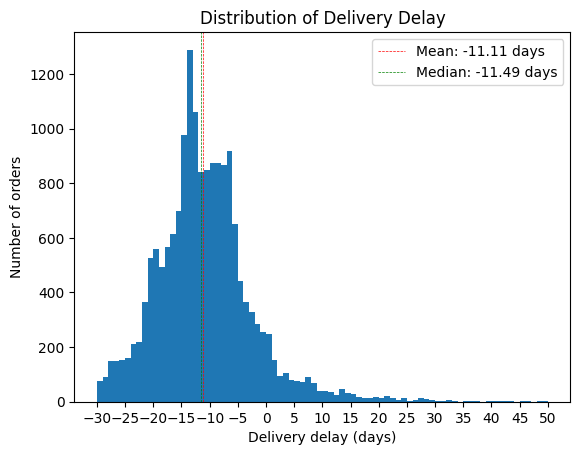

In [54]:
import matplotlib.pyplot as plt

delay_days = delay.dt.total_seconds() / (24 * 60 * 60)

mean_delay = delay_days.mean()
median_delay = delay_days.median()

plt.hist(delay_days.dropna(), bins=range(-30, 51))

plt.axvline(mean_delay, linestyle="--", linewidth=0.5, color="red",
            label=f"Mean: {mean_delay:.2f} days")

plt.axvline(median_delay, linestyle="--", linewidth=0.5, color="green",
            label=f"Median: {median_delay:.2f} days")

plt.xlabel("Delivery delay (days)")
plt.ylabel("Number of orders")
plt.title("Distribution of Delivery Delay")
plt.xticks(range(-30, 51, 5))
plt.legend()

plt.show()

In [55]:
# Headline numbers, computed strictly on the labelled subset
late_orders = labelled[labelled["delivered_after_estimate"] == 1]
late_days = (
    late_orders["order_delivered_customer_date"].dt.normalize()
    - late_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

late_rate = float(labelled["delivered_after_estimate"].mean())
q1_stats = {
    "labelled": n_labelled, "late": n_late, "on_time": n_ontime,
    "late_rate": late_rate,
    "median_late_days": float(late_days.median()),
    "mean_late_days": float(late_days.mean()),
    "p90_late_days": float(late_days.quantile(0.9)),
    "max_late_days": float(late_days.max()),
    "share_over_7d": float((late_days > 7).mean()),
}
print(f"late-delivery rate: {late_rate:.1%}  ({n_late:,} of {n_labelled:,} labelled orders)")
print(f"delay among late orders (days): median {q1_stats['median_late_days']:.1f} | "
      f"mean {q1_stats['mean_late_days']:.1f} | p90 {q1_stats['p90_late_days']:.0f} | "
      f"max {q1_stats['max_late_days']:.0f}")
print(f"late orders slipping more than a week: {q1_stats['share_over_7d']:.1%}")

late-delivery rate: 6.8%  (1,105 of 16,262 labelled orders)
delay among late orders (days): median 7.0 | mean 10.6 | p90 22 | max 188
late orders slipping more than a week: 44.6%


**Answer (Q1).** Of 16,262 labelled orders, 1,105 arrived after the estimated date — a late-delivery rate of **6.8%** (15,157 on time or early). The distribution above shows most completed deliveries actually arrive *before* the estimate (mass left of 0).

When orders are late, they are late by **7.0 days** (median), 10.6 days on average and 22 days at the 90th percentile, up to 188 days in the worst case; 44.6% of late orders slip by more than a week.

Data-quality caveat: this rate covers the 16,262 usable completed deliveries (85.8% of the analysis set); cancelled and unreliable orders are unlabelled by design, and Section 3.5 shows the rate is stable under alternative definitions.

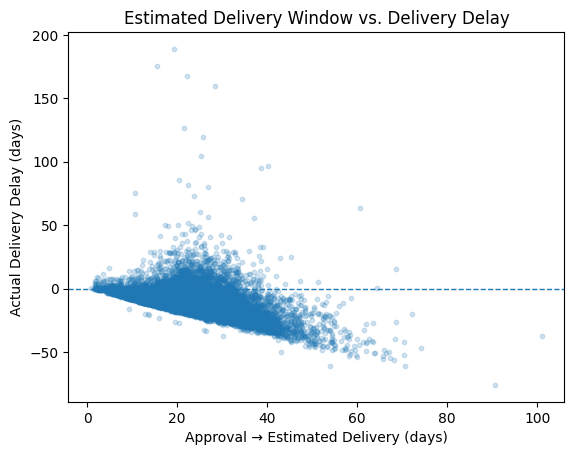

In [56]:
# Approval → estimated delivery window (days)
time_window = (
    order_clean_df["order_estimated_delivery_date"]
    - order_clean_df["order_approved_at"]
).dt.total_seconds() / (24 * 60 * 60)

# Estimated → actual delivery delay (days)
delay_days = (
    order_clean_df["order_delivered_customer_date"]
    - order_clean_df["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Keep only valid values
mask = time_window.notna() & delay_days.notna()

plt.scatter(
    time_window[mask],
    delay_days[mask],
    alpha=0.2,
    s=10
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Approval → Estimated Delivery (days)")
plt.ylabel("Actual Delivery Delay (days)")
plt.title("Estimated Delivery Window vs. Delivery Delay")

plt.show()

,late_rate,n
window,,
1-7,0.165517,290
8-14,0.049608,1915
15-21,0.070974,4086
22-28,0.075887,5640
29-42,0.058612,3617
>42,0.017413,402


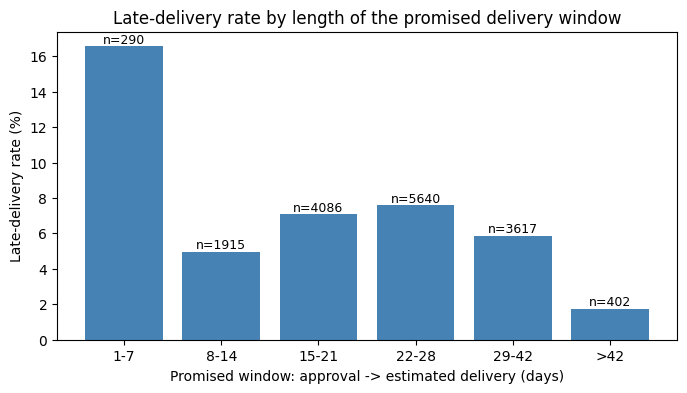

point-biserial correlation (window vs late): -0.032
labelled orders without an approval timestamp (dropped here): 312


In [57]:
# Late rate by the length of the promised window (approval -> estimated date)
window_days = (
    order_clean_df["order_estimated_delivery_date"].dt.normalize()
    - order_clean_df["order_approved_at"].dt.normalize()
).dt.days

q2 = (
    labelled.assign(
        window=pd.cut(
            window_days[labelled.index],
            bins=[-np.inf, 0, 7, 14, 21, 28, 42, np.inf],
            labels=["<=0", "1-7", "8-14", "15-21", "22-28", "29-42", ">42"],
        )
    )
    .groupby("window", observed=True)["delivered_after_estimate"]
    .agg(late_rate="mean", n="count")
)
display(q2)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(q2.index.astype(str), q2["late_rate"] * 100, color="steelblue")
for i, (rate, n) in enumerate(zip(q2["late_rate"], q2["n"])):
    ax.text(i, rate * 100, f"n={n}", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Promised window: approval -> estimated delivery (days)")
ax.set_ylabel("Late-delivery rate (%)")
ax.set_title("Late-delivery rate by length of the promised delivery window")
plt.show()

q2_corr = float(
    labelled.assign(window=window_days[labelled.index])
    [["delivered_after_estimate", "window"]].corr().iloc[0, 1]
)
n_q2_missing = int(labelled["order_approved_at"].isna().sum())
print(f"point-biserial correlation (window vs late): {q2_corr:.3f}")
print(f"labelled orders without an approval timestamp (dropped here): {n_q2_missing}")

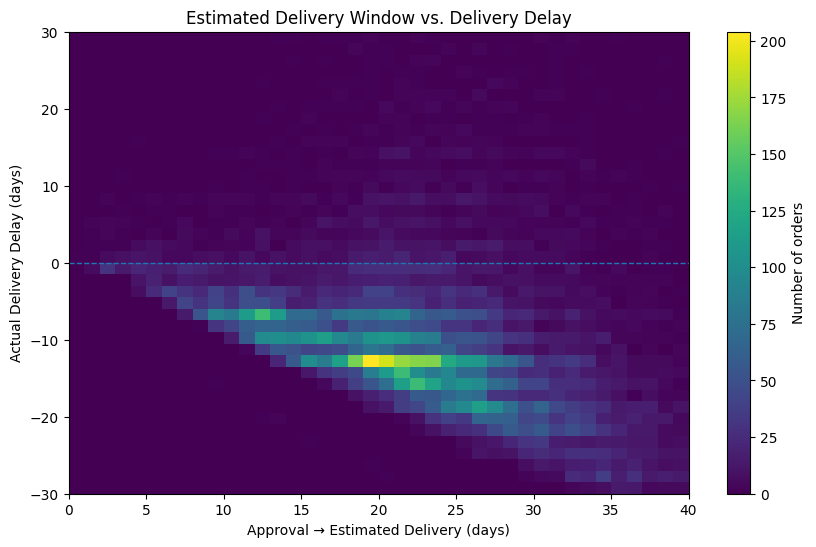

In [58]:
plt.figure(figsize=(10, 6))

plt.hist2d(
    time_window[mask],
    delay_days[mask],
    bins=[40, 40],
    range=[[0, 40], [-30, 30]],
    cmap="viridis"
)

plt.colorbar(label="Number of orders")
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Approval → Estimated Delivery (days)")
plt.ylabel("Actual Delivery Delay (days)")
plt.title("Estimated Delivery Window vs. Delivery Delay")

plt.show()

**Answer (Q2).** The promised window relates **negatively** to lateness: orders given more time are late less often.

| Promised window | Labelled orders | Late rate |
|---|---|---|
| 1-7 days | 290 | 16.6% |
| 8-14 days | 1,915 | 5.0% |
| 15-21 days | 4,086 | 7.1% |
| 22-28 days | 5,640 | 7.6% |
| 29-42 days | 3,617 | 5.9% |
| >42 days | 402 | 1.7% |

Point-biserial correlation between window length and the label: **-0.032** (n = 16,262 labelled orders).

Caveat: the estimated date is set by the marketplace *at approval* and already absorbs known difficulty (distance, seller history), so this is an association — longer windows do not *cause* fewer delays. The scatter/2-D histogram above also shows late deliveries cluster at short windows *and* large positive delays. 312 labelled orders without an approval timestamp drop out of this view.

In [59]:
order_clean_df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,payment_count,total_payment,max_installments,payment_types,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,min_price,...,shipping_limit_min,shipping_limit_max,avg_name_length,avg_description_length,avg_photos_qty,total_weight_g,avg_weight_g,avg_length_cm,avg_height_cm,avg_width_cm,unique_seller_cities,unique_seller_states,main_seller_city,main_seller_state,customer_unique_id,customer_city,customer_state,actually_delivered,has_review,price_outlier_flag,main_seller_city_normalized,customer_city_normalized,customer_zip_code_prefix_cleaned,date_is_logical,delivered_after_estimate
0,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,NaT,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,e73b67b67587f7644d5bd1a52deb1b01,5.0,None,None,2018-08-18,2018-08-22 19:07:58,1,179.12,3,1,1.0,1.0,1.0,1.0,159.90,159.900,159.90,...,2018-08-13 08:55:23,2018-08-13 08:55:23,46.0,232.0,NaN,420.0,420.0,24.0,19.0,21.0,1.0,1.0,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,True,True,False,guariba,vianopolis,75265,True,0.0
1,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06,fc4af8aea8ec3f1a3cd181d3d0cadbd5,1.0,None,None,2017-02-03,2017-02-05 01:58:35,1,35.95,1,1,1.0,1.0,1.0,1.0,19.90,19.900,19.90,...,2017-01-27 18:29:09,2017-01-27 18:29:09,41.0,432.0,2.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,sao jose do rio pardo,ZZ,39382392765b6dc74812866ee5ee92a7,faxinalzinho,RS,True,True,False,sao jose do rio pardo,faxinalzinho,99655,True,0.0
2,403b97836b0c04a622354cf531062e5f,7acc63bb81a1111a922c238549b85dde,delivered,2018-01-02 19:00:43,2018-01-02 19:09:04,2018-01-03 18:19:09,2018-01-20 01:38:59,2018-02-06,NaN,NaN,NaN,NaN,NaT,NaT,1,1376.45,10,1,1.0,1.0,1.0,1.0,1299.00,1299.000,1299.00,...,2018-01-12 19:09:04,2018-01-12 19:09:04,38.0,143.0,2.0,20850.0,20850.0,100.0,25.0,50.0,1.0,1.0,mogi das cruzes,SP,NaN,NaN,NaN,True,False,False,mogi das cruzes,None,<NA>,True,0.0
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,70c498f6918af37d6444d7846449ea5b,5.0,None,None,2017-11-28,2017-11-28 22:12:02,1,29.75,1,1,1.0,1.0,1.0,1.0,17.90,17.900,17.90,...,NaT,NaT,43.0,125.0,1.0,250.0,250.0,40.0,4.0,30.0,1.0,1.0,ibitinga,SP,d0ff1a7468fcc46b8fc658ab35d2a12c,hortolandia,SP,True,True,False,ibitinga,hortolandia,<NA>,True,0.0
4,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,canceled,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,0153550f6dd1a6bdfc334a919622abfb,4.0,None,None,2018-03-28,2018-03-29 16:38:11,1,63.34,3,1,1.0,1.0,1.0,1.0,30.10,30.100,30.10,...,2018-03-01 14:28:03,2018-03-01 14:28:03,56.0,1313.0,2.0,850.0,850.0,20.0,20.0,20.0,0.0,0.0,None,None,1428917cd397d4f9ac0fde76dd6f2266,boa vista,RR,True,True,False,None,boa vista,69317,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,7cc85185736ea7f2d8bc09af7a47cab7,be7f04c7b3e94f9bdd609570b64becf2,delivered,2017-05-15 09:46:26,2017-05-15 10:02:45,2017-05-15 14:11:06,2017-05-22 18:05:56,2017-06-07,8201776e432c858dd2c04451c9c71728,5.0,None,None,2017-05-23,2017-05-27 01:18:26,1,194.91,10,1,1.0,1.0,1.0,1.0,179.90,179.900,179.90,...,2017-05-22 10:02:45,2017-05-22 10:02:45,57.0,287.0,1.0,450.0,450.0,23.0,8.0,15.0,1.0,1.0,campinas,SP,NaN,NaN,NaN,True,True,False,campinas,None,<NA>,True,0.0
19996,b0f4af5c1b06e24fef510703bfe9f0a6,8

### Q3 — How do late-delivery rates vary across customer states?

Rates are computed per state on labelled orders; the chart that follows restricts to states with **n ≥ 30** labelled orders and shows 95% Wilson confidence intervals, so wide-interval states are not over-interpreted.

In [60]:
q3 = (
    labelled.groupby("customer_state")["delivered_after_estimate"]
    .agg(late_rate="mean", n="count")
    .sort_values(["late_rate", "n"], ascending=[False, False])
)
overall_late_rate = float(labelled["delivered_after_estimate"].mean())
print(f"states with labelled orders: {labelled['customer_state'].nunique()}")
display(q3.head(12))

states with labelled orders: 28


,late_rate,n
customer_state,,
RR,0.222222,9
CE,0.175824,182
MA,0.175000,120
AL,0.171429,70
PE,0.155556,225
PI,0.150685,73
BA,0.120000,500
PA,0.117647,136
RJ,0.115806,1917


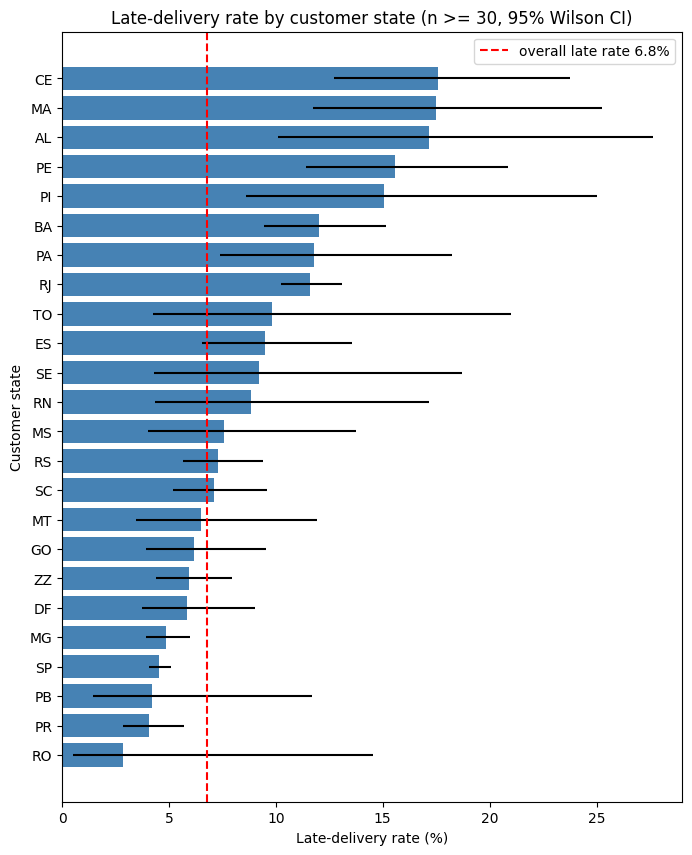

Top 5 states by late rate: ['RR', 'CE', 'MA', 'AL', 'PE']


In [61]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


q3[["ci_low", "ci_high"]] = [wilson_ci(r * n, n) for r, n in zip(q3["late_rate"], q3["n"])]

q3_plot = q3[q3["n"] >= 30]
fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(q3_plot))
ax.barh(y, q3_plot["late_rate"] * 100,
        xerr=[(q3_plot["late_rate"] - q3_plot["ci_low"]) * 100,
              (q3_plot["ci_high"] - q3_plot["late_rate"]) * 100],
        color="steelblue")
ax.set_yticks(y)
ax.set_yticklabels(q3_plot.index)
ax.invert_yaxis()
ax.axvline(overall_late_rate * 100, ls="--", c="red",
           label=f"overall late rate {overall_late_rate:.1%}")
ax.set_xlabel("Late-delivery rate (%)")
ax.set_ylabel("Customer state")
ax.set_title("Late-delivery rate by customer state (n >= 30, 95% Wilson CI)")
ax.legend()
plt.show()

q3_top8 = q3.head(8).reset_index().to_dict("records")
top5_base = q3.head(5).index.tolist()
print("Top 5 states by late rate:", top5_base)

**Answer (Q3).** Overall late rate: **6.8%**. States with the highest late-delivery rates (among those with n ≥ 30 labelled orders):

| State | Labelled orders | Late rate | 95% CI |
|---|---|---|---|
| CE | 182 | 17.6% | 12.7%-23.8% |
| MA | 120 | 17.5% | 11.7%-25.3% |
| AL | 70 | 17.1% | 10.1%-27.6% |
| PE | 225 | 15.6% | 11.4%-20.9% |
| PI | 73 | 15.1% | 8.6%-25.0% |
| BA | 500 | 12.0% | 9.4%-15.1% |
| PA | 136 | 11.8% | 7.4%-18.3% |

Operations should investigate **CE** first (17.6% late, n = 182, 95% CI 12.7%-23.8%), with MA and AL next. Its interval lies entirely above the overall rate, so the gap is unlikely to be noise; the next states overlap each other, so treat their ordering as indicative.

### 3.5 Sensitivity and confidence

The answers above depend on inclusion rules, so recompute the headline late rate under four alternative definitions. The unlabelled share bounds how far the true rate could differ.

In [62]:
variants = {}

# Base: calendar-date comparison on the date-logical analysis set
variants["Base (calendar-date comparison)"] = labelled["delivered_after_estimate"]

# V1: compare raw timestamps instead of calendar dates
v1 = pd.Series(
    np.where(order_clean_df["order_delivered_customer_date"]
             > order_clean_df["order_estimated_delivery_date"], 1, 0),
    index=order_clean_df.index,
).where(usable)
variants["V1: timestamp comparison (same-day PM counts late)"] = v1

# V2: keep the date-illogical rows too
usable2 = (
    order_raw_df["order_status"].eq("delivered")
    & order_raw_df["order_delivered_customer_date"].notna()
    & order_raw_df["order_estimated_delivery_date"].notna()
    & order_raw_df["actually_delivered"].fillna(False)
)
d_raw = order_raw_df["order_delivered_customer_date"].dt.normalize()
e_raw = order_raw_df["order_estimated_delivery_date"].dt.normalize()
v2 = pd.Series(np.where(d_raw > e_raw, 1, 0), index=order_raw_df.index).where(usable2)
variants["V2: include date-illogical orders"] = v2

# V3: usable = status + dates only (ignore item availability)
usable3 = (
    order_clean_df["order_status"].eq("delivered")
    & order_clean_df["order_delivered_customer_date"].notna()
    & order_clean_df["order_estimated_delivery_date"].notna()
)
v3 = pd.Series(np.where(d_day > e_day, 1, 0), index=order_clean_df.index).where(usable3)
variants["V3: usable = status + dates only"] = v3

# V4: additionally require a carrier handover date
usable4 = usable & order_clean_df["order_delivered_carrier_date"].notna()
v4 = pd.Series(np.where(d_day > e_day, 1, 0), index=order_clean_df.index).where(usable4)
variants["V4: also require carrier handover date"] = v4

sens = pd.DataFrame({
    "n labelled": [int(v.notna().sum()) for v in variants.values()],
    "late rate": [float(v.mean()) for v in variants.values()],
}, index=list(variants.keys()))
sens["delta vs base (pp)"] = (sens["late rate"] - sens["late rate"].iloc[0]) * 100
display(sens.round(4))

sens_table = sens.reset_index().rename(columns={"index": "definition"}).to_dict("records")

top5_v2 = (
    order_raw_df.loc[v2.notna()]
    .assign(label=v2[v2.notna()].values)
    .groupby("customer_state")["label"].mean()
    .sort_values(ascending=False).head(5).index.tolist()
)
print("Top 5 states - base:", top5_base)
print("Top 5 states - V2  :", top5_v2)

,n labelled,late rate,delta vs base (pp)
Base (calendar-date comparison),16262,0.0679,0.0000
V1: timestamp comparison (same-day PM counts late),16262,0.0820,1.4082
V2: include date-illogical orders,17273,0.0641,-0.3861
V3: usable = status + dates only,16262,0.0679,0.0000
V4: also require carrier handover date,15968,0.0681,0.0186


Top 5 states - base: ['RR', 'CE', 'MA', 'AL', 'PE']
Top 5 states - V2  : ['RR', 'CE', 'MA', 'AL', 'PE']


**Reading.** The headline late rate stays within **6.4%-8.2%** across all five definitions, so the Q1 answer is not an artefact of one arbitrary choice. The state ranking is similarly stable: the top five states are identical under the base and V2 definitions (RR, CE, MA, AL, PE).

Confidence: rates are measured on 16,262 labelled orders (85.8% of the analysis set). The Wilson intervals on the Q3 chart show which state differences are distinguishable from noise — small states with wide intervals should not drive decisions. Per the brief, these are associations in this modified extract; they do not establish causation.

In [63]:
# Machine-readable summary of Section 1-3 results (reused by the report in Section 5)
import json

summary = {
    "loading": {
        "db_size_mb": round(db_size_mb, 1),
        "table_rows": table_rows,
        "duplicate_keys": pk_checks,
        "orphan_rows": fk_results,
        "review_dup_rows": review_dup_rows,
        "orders_matched_review": orders_matched_review,
        "payment_total_diff": pay_diff,
        "items_price_diff": items_price_diff,
        "items_freight_diff": items_freight_diff,
        "item_rows": int(len(item_df)),
        "sum_item_count": sum_item_count,
        "orders_without_items": int(order_df_v4["item_count"].isna().sum()),
        "customer_match_rate": round(float(order_raw_df["customer_unique_id"].notna().mean()), 4),
        "memory_mb": {k: round(v, 1) for k, v in mem.items()},
    },
    "cleaning": {
        "status_recased": n_status_fixed,
        "states_recased_trimmed": n_state_fixed,
        "invalid_review_scores": n_bad_score,
        "negative_payments": n_neg_pay,
        "negative_freight": n_neg_freight,
        "negative_price": n_neg_price,
        "price_outliers_flagged": n_price_out,
        "invalid_zip": invalid_zip_n,
        "city_unmatched": city_unmatched_n,
        "date_illogical_excluded": date_illogical_n,
        "orders_without_item_rows": no_items_n,
        "missing_customer_location": missing_loc_n,
    },
    "label": {
        "analysis_set": n_analysis,
        "labelled": n_labelled,
        "late": n_late,
        "on_time": n_ontime,
        "unlabelled": n_analysis - n_labelled,
        "exclusion_reasons": label_exclusion_reasons,
    },
    "q1": q1_stats,
    "q2": {
        "buckets": q2.reset_index().to_dict("records"),
        "correlation": q2_corr,
        "missing_approved": n_q2_missing,
    },
    "q3": {
        "overall_late_rate": overall_late_rate,
        "top_states": q3_top8,
        "top5_base": top5_base,
        "top5_v2": top5_v2,
    },
    "sensitivity": {"table": sens_table},
}

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
(out_dir / "analysis_summary.json").write_text(
    json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
)
print("saved outputs/analysis_summary.json")

saved outputs/analysis_summary.json


# 4. Feature Engineering (20%)

A numerical feature table for a future late-delivery prediction model: **one row per retained order**, built from **only information available at approval**. The model inputs are delivered as separate files so that IDs and labels never sit inside the feature matrix:

- `outputs/features.csv` — the feature matrix (row key `order_id` in the index; it is a join key, **not** a predictor)
- `outputs/labels.csv` — `delivered_after_estimate` per order (`NaN` = unlabelled per the brief)
- `outputs/feature_dictionary.csv` — meaning, dtype and missing-policy of every feature

The retained set is the cleaned analysis set (`order_clean_df`, 18,954 orders): the 1,046 date-illogical orders are not retained, because their contradictory event history makes both features and labels unreliable.

### 4.1 Leakage rules — what the model may see

Per the brief, **available at approval**: basket contents, prices and freight, the estimated delivery date, customer location, and product/seller attributes.

**Banned as predictors**: payments, final status, shipment/delivery events, reviews, and `shipping_limit_date` — all of these only exist after approval (most only after delivery) and would leak the outcome. Derived flags that depend on them (e.g. `actually_delivered`, which uses `order_status`) are banned too. The assembly cell below asserts that none of them are present.

In [64]:
base = order_clean_df.copy()

# If approval is missing, the purchase timestamp is the best known pre-approval time.
base["approval_effective"] = base["order_approved_at"].fillna(base["order_purchase_timestamp"])
base["approved_missing"] = base["order_approved_at"].isna().astype(int)

# Columns that must NEVER appear in the feature table (post-approval information).
leakage_banned = [
    # payments
    "payment_count", "total_payment", "max_installments", "payment_types",
    # final status and anything derived from it
    "order_status", "actually_delivered",
    # shipment / delivery events
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "shipping_limit_min", "shipping_limit_max",
    # reviews and review-derived flags
    "review_id", "review_score", "review_score_filled",
    "review_creation_date", "review_answer_timestamp", "has_review",
    # label / post-hoc helpers
    "delivered_after_estimate", "delivery_delay_days", "date_is_logical",
]
print(f"base: {len(base):,} retained orders; {len(leakage_banned)} column names banned as predictors")

base: 18,954 retained orders; 19 column names banned as predictors


### 4.2 Numerical features

Basket composition, prices/freight (BRL after the Section-2 unit fix), product/handling attributes, and derived ratios. Missing values stay `NaN` — zero-filling would fake information — with explicit `_missing` flags where absence itself is informative.

In [65]:
feat_num = pd.DataFrame(index=base.index)

# Basket composition (order_items grain aggregated in Section 1)
feat_num["item_count"] = base["item_count"]
feat_num["unique_products"] = base["unique_products"]
feat_num["unique_sellers"] = base["unique_sellers"]
feat_num["unique_categories"] = base["unique_categories"]

# Money: prices and freight only — payment columns are banned
feat_num["total_price"] = base["total_price"]
feat_num["avg_price"] = base["avg_price"]
feat_num["max_price"] = base["max_price"]
feat_num["total_freight"] = base["total_freight"]
feat_num["freight_ratio"] = base["total_freight"] / (base["total_price"] + 1.0)   # logistics intensity
feat_num["price_per_item"] = base["total_price"] / base["item_count"]             # basket value density

# Product / handling attributes (optional catalogue fields -> NaN kept, flagged)
feat_num["total_weight_g"] = base["total_weight_g"]
feat_num["avg_weight_g"] = base["avg_weight_g"]
feat_num["volume_cm3"] = base["avg_length_cm"] * base["avg_height_cm"] * base["avg_width_cm"]
feat_num["avg_description_length"] = base["avg_description_length"]
feat_num["avg_photos_qty"] = base["avg_photos_qty"]

# Seller-customer geography spread
feat_num["unique_seller_states"] = base["unique_seller_states"]

# Short-haul proxy: does the main seller sit in the customer's state?
both_states = base["customer_state"].notna() & base["main_seller_state"].notna()
feat_num["seller_customer_same_state"] = pd.Series(
    np.where(both_states, (base["customer_state"] == base["main_seller_state"]).astype(float), np.nan),
    index=base.index,
)

# Missingness flags (missing catalogue data may itself predict delay)
feat_num["items_missing"] = base["item_count"].isna().astype(int)
feat_num["weight_missing"] = base["total_weight_g"].isna().astype(int)

print(f"{len(feat_num.columns)} numerical features")

19 numerical features


### 4.3 Date/time features

All times are reduced to approval-relative numbers. The flagship feature is `promised_window_days` (estimated date − approval), which Section 3 showed carries the clearest signal. Clock/calendar positions use **cyclical sin/cos encoding** so that, e.g., 23:00 and 00:00 are close together instead of 23 units apart.

In [66]:
feat_dt = pd.DataFrame(index=base.index)

# How much time the marketplace promised (calendar days)
feat_dt["promised_window_days"] = (
    base["order_estimated_delivery_date"].dt.normalize()
    - base["approval_effective"].dt.normalize()
).dt.days

# Friction between purchase and approval (hours)
feat_dt["purchase_to_approval_hours"] = (
    base["approval_effective"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 3600.0

# Cyclical encodings of the approval moment
hour = base["approval_effective"].dt.hour
dow = base["approval_effective"].dt.dayofweek
month = base["approval_effective"].dt.month
for name, series, period in [("hour", hour, 24), ("dow", dow, 7), ("month", month, 12)]:
    feat_dt[f"approval_{name}_sin"] = np.sin(2 * np.pi * series / period)
    feat_dt[f"approval_{name}_cos"] = np.cos(2 * np.pi * series / period)

feat_dt["approved_missing"] = base["approved_missing"]

print(f"{len(feat_dt.columns)} date/time features")

9 date/time features


### 4.4 Categorical features

- **States** (`customer_state`, `main_seller_state`): one-hot encoding — ~30 levels each, so the full binary set stays manageable and the model can weight every region. `dummy_na=True` gives missing values their own indicator instead of silently dropping rows.
- **City**: thousands of distinct normalised names, so one-hot would explode the table with sparse columns. Frequency encoding (how common the customer's city is) keeps one informative, consistently-defined numeric column.
- **Raw ZIP prefix**: dropped — it duplicates geography already carried by state + city frequency, and as a number it implies a fake ordering.

In [67]:
feat_cat = pd.DataFrame(index=base.index)

cust_state_dummies = pd.get_dummies(base["customer_state"], prefix="cust_state",
                                    dummy_na=True, dtype="int8")
sell_state_dummies = pd.get_dummies(base["main_seller_state"], prefix="sell_state",
                                    dummy_na=True, dtype="int8")

city_freq = base["customer_city_normalized"].value_counts(normalize=True, dropna=True)
feat_cat["customer_city_freq"] = base["customer_city_normalized"].map(city_freq)

feat_cat = pd.concat([feat_cat, cust_state_dummies, sell_state_dummies], axis=1)
print(f"{len(feat_cat.columns)} categorical-encoded features "
      f"(1 frequency + {len(cust_state_dummies.columns)} customer-state + {len(sell_state_dummies.columns)} seller-state)")

53 categorical-encoded features (1 frequency + 29 customer-state + 23 seller-state)


### 4.5 Assemble, verify, save

The assembled table is checked before saving: right number of unique rows, every column numeric, and **no banned (leakage) column present**. IDs and labels are written to separate files.

In [68]:
feature_table = pd.concat([feat_num, feat_dt, feat_cat], axis=1)
feature_table.index = base["order_id"].to_numpy()
feature_table.index.name = "order_id"

labels = base[["delivered_after_estimate"]].copy()
labels.index = feature_table.index
labels.index.name = "order_id"

# --- checks: shape, uniqueness, dtype purity, freedom from leakage ---
assert len(feature_table) == len(order_clean_df), "row count changed"
assert feature_table.index.is_unique, "duplicate order_id in feature table"
assert all(pd.api.types.is_numeric_dtype(t) for t in feature_table.dtypes), "non-numeric column found"
leaked = sorted(set(leakage_banned) & set(feature_table.columns))
assert not leaked, f"leakage columns present: {leaked}"
assert labels["delivered_after_estimate"].notna().sum() == n_labelled, "labels mismatch vs Section 3"

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
feature_table.to_csv(out_dir / "features.csv")
labels.to_csv(out_dir / "labels.csv")

print(f"features: {feature_table.shape[0]:,} rows x {feature_table.shape[1]} features -> outputs/features.csv")
print(f"labels:   {labels['delivered_after_estimate'].notna().sum():,} labelled "
      f"({labels['delivered_after_estimate'].isna().sum():,} unlabelled kept as NaN) -> outputs/labels.csv")
print(f"label join check: index identical to features -> {labels.index.equals(feature_table.index)}")

features: 18,954 rows x 81 features -> outputs/features.csv
labels:   16,262 labelled (2,692 unlabelled kept as NaN) -> outputs/labels.csv
label join check: index identical to features -> True


### 4.6 What each feature means, and what was kept or dropped

**Kept (and why):**
- *Basket*: `item_count`, `unique_products/sellers/categories` — bigger, more complex baskets need more handling.
- *Money*: totals plus `freight_ratio` (freight relative to basket value — remote/awkward routes charge proportionally more) and `price_per_item` (single expensive item vs many cheap ones ship differently). `min_price` was dropped as redundant with avg/max.
- *Handling*: weight and `volume_cm3` proxy physical effort; description length and photo count proxy catalogue quality. Missingness is flagged, never zero-filled.
- *Time*: `promised_window_days` (strongest EDA signal), approval-to-purchase friction, cyclical hour/weekday/month for seasonality.
- *Geography*: state one-hots (regional risk, e.g. CE/MA/AL in Q3), `seller_customer_same_state` (short-haul proxy), `customer_city_freq` (metropolitan vs remote).

**Dropped (and why):** payments, final status, delivery events, `shipping_limit_date`, reviews — banned by the brief (leakage); raw city names and ZIP prefixes (cardinality / fake ordinality, geography already represented).

**Consistency:** every column is numeric (`int8` binaries, `float64` elsewhere); missingness is either `NaN` + flag or a dedicated indicator column — never a magic number.

In [69]:
# Feature dictionary + machine-readable summary for the report
desc = {
    "item_count": ("numeric", "items in the basket", "nunique order_item_id per order", "NaN = no item rows (flagged by items_missing)"),
    "unique_products": ("numeric", "distinct products in the basket", "nunique product_id", "NaN = no item rows"),
    "unique_sellers": ("numeric", "distinct sellers in the basket", "nunique seller_id", "NaN = no item rows"),
    "unique_categories": ("numeric", "distinct product categories", "nunique product_category_name", "NaN = no item rows"),
    "total_price": ("numeric", "basket value in BRL", "sum of item prices", "NaN if all item prices missing"),
    "avg_price": ("numeric", "mean item price in BRL", "mean of item prices", "NaN if all missing"),
    "max_price": ("numeric", "most expensive item in BRL", "max of item prices", "NaN if all missing"),
    "total_freight": ("numeric", "total freight in BRL", "sum of freight_value", "NaN if all missing; negatives removed in Section 2"),
    "freight_ratio": ("numeric", "freight / (basket value + 1)", "derived", "NaN if freight missing"),
    "price_per_item": ("numeric", "basket value per item", "total_price / item_count", "NaN if no items"),
    "total_weight_g": ("numeric", "total basket weight in grams", "sum of product_weight_g", "NaN = catalogue gap (flagged by weight_missing)"),
    "avg_weight_g": ("numeric", "mean item weight in grams", "mean of product_weight_g", "NaN = catalogue gap"),
    "volume_cm3": ("numeric", "mean item volume (L*H*W cm)", "product of mean dimensions", "NaN if any dimension missing"),
    "avg_description_length": ("numeric", "mean product description length (chars)", "mean of product_description_lenght", "NaN = optional catalogue field"),
    "avg_photos_qty": ("numeric", "mean product photo count", "mean of product_photos_qty", "NaN = optional catalogue field"),
    "unique_seller_states": ("numeric", "number of states the sellers ship from", "nunique seller_state", "NaN = no item rows"),
    "seller_customer_same_state": ("numeric", "1 if main seller state equals customer state", "derived comparison", "NaN if either state missing"),
    "items_missing": ("binary flag", "1 if the order has no item rows", "derived", "never NaN"),
    "weight_missing": ("binary flag", "1 if basket weight unknown", "derived", "never NaN"),
    "promised_window_days": ("numeric", "calendar days from approval to estimated delivery", "estimated date - approval (purchase fallback)", "NaN if both dates missing"),
    "purchase_to_approval_hours": ("numeric", "hours from purchase to approval", "approval - purchase timestamps", "NaN if both missing"),
    "approval_hour_sin/cos": ("cyclical", "time of day of approval (24h cycle)", "sin/cos of hour", "NaN if approval time unknown"),
    "approval_dow_sin/cos": ("cyclical", "weekday of approval (7d cycle)", "sin/cos of day-of-week", "NaN if unknown"),
    "approval_month_sin/cos": ("cyclical", "month of approval (12m cycle)", "sin/cos of month", "NaN if unknown"),
    "approved_missing": ("binary flag", "1 if approval timestamp absent (purchase used instead)", "derived", "never NaN"),
    "customer_city_freq": ("frequency", "share of orders from the customer's normalised city", "value_counts(normalize) mapping", "NaN if city unmatched"),
}

rows = []
for col in feature_table.columns:
    if col in desc:
        kind, meaning, derivation, missing = desc[col]
    elif col.startswith("cust_state_"):
        state = col[len("cust_state_"):]
        kind, meaning = "binary one-hot", f"customer state = {state}"
        derivation, missing = "one-hot of customer_state", "cust_state_nan = 1 flags missing state"
    elif col.startswith("sell_state_"):
        state = col[len("sell_state_"):]
        kind, meaning = "binary one-hot", f"main seller state = {state}"
        derivation, missing = "one-hot of main_seller_state", "sell_state_nan = 1 flags missing state"
    else:
        kind, meaning, derivation, missing = "numeric", col, "-", "-"
    rows.append({"feature": col, "kind": kind, "dtype": str(feature_table[col].dtype),
                 "meaning": meaning, "derivation": derivation, "missing_policy": missing})

feature_dictionary = pd.DataFrame(rows)
feature_dictionary.to_csv(out_dir / "feature_dictionary.csv", index=False)

features_summary = {
    "n_orders": int(len(feature_table)),
    "n_features": int(feature_table.shape[1]),
    "n_binary_onehot": int(sum(feature_dictionary["kind"] == "binary one-hot")),
    "n_labelled": int(labels["delivered_after_estimate"].notna().sum()),
    "columns": feature_table.dtypes.astype(str).to_dict(),
    "missing_counts": {k: int(v) for k, v in feature_table.isna().sum().items() if v > 0},
    "leakage_banned_checked": leakage_banned,
}
(out_dir / "features_summary.json").write_text(json.dumps(features_summary, indent=2))
print(f"feature dictionary: {len(feature_dictionary)} rows -> outputs/feature_dictionary.csv")
print(f"summary -> outputs/features_summary.json")
feature_table.iloc[:3, :12]

feature dictionary: 81 rows -> outputs/feature_dictionary.csv
summary -> outputs/features_summary.json


,item_count,unique_products,unique_sellers,unique_categories,total_price,avg_price,max_price,total_freight,freight_ratio,price_per_item,total_weight_g,avg_weight_g
order_id,,,,,,,,,,,,
47770eb9100c2d0c44946d9cf07ec65d,1.0,1.0,1.0,1.0,159.9,159.9,159.9,19.22,0.119453,159.9,420.0,420.0
76c6e866289321a7c93b82b54852dc33,1.0,1.0,1.0,1.0,19.9,19.9,19.9,NaN,NaN,19.9,0.0,NaN
403b97836b0c04a622354cf531062e5f,1.0,1.0,1.0,1.0,1299.0,1299.0,1299.0,77.45,0.059577,1299.0,20850.0,20850.0


### 4.7 SHAP sanity check — does the leakage-free table carry signal?

The brief asks for a *model-ready* table, not a model — but a feature table is only useful if it genuinely supports prediction. So this subsection runs a clearly-labelled **sanity check**: a quick gradient-boosted classifier is trained on the labelled subset and inspected with **SHAP** (SHapley Additive exPlanations), which attributes every prediction to the features that produced it.

- **No new information enters the table.** The model reads exactly the `features.csv` + `labels.csv` pair validated in 4.5 — every column already passed the leakage assertions, so whatever SHAP finds is leakage-free by construction.
- **No imputation.** `HistGradientBoostingClassifier` treats `NaN` as its own split direction, so the table's deliberate missingness (4.2–4.4) survives intact — consistent with leaving imputation to the modelling stage.
- **Honest performance number.** Stratified 5-fold cross-validated ROC AUC; with a 6.8% late rate, accuracy would be misleading.
- **Attribution.** `shap.TreeExplainer` Shapley values on a fixed random sample of 3,000 labelled orders; feature importance = mean |SHAP| across orders. Saved as `outputs/shap_importance.csv`, `outputs/shap_beeswarm.png` and `outputs/shap_summary.json` for the report.

This is a *diagnostic of the feature table*, not a deliverable model — no tuning, no deployment claims, and SHAP associations (like the rest of the report) do not establish causation.


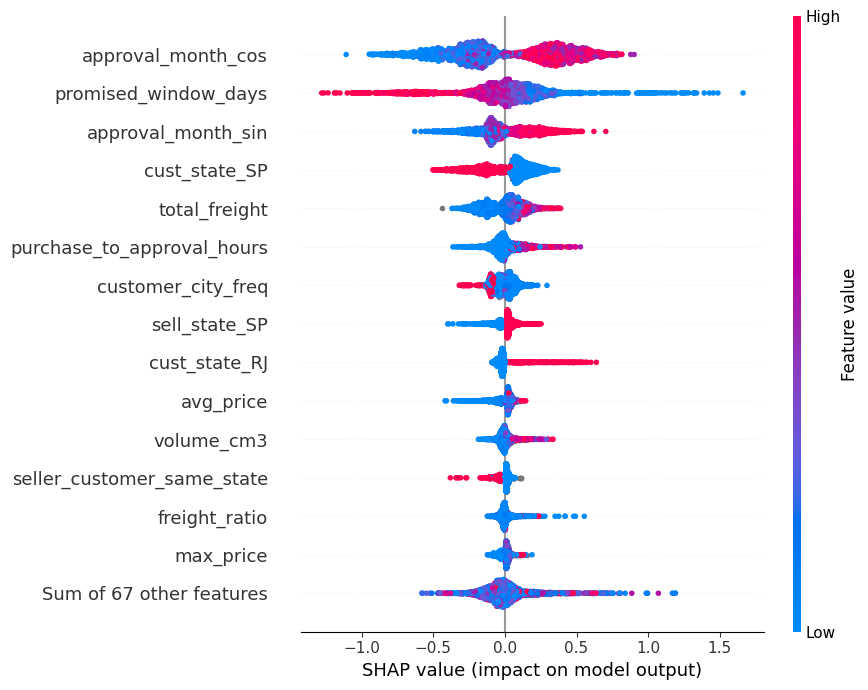

5-fold CV ROC AUC: 0.744 +/- 0.011 (16,262 labelled orders, late rate 6.8%)

Top 15 features by mean |SHAP|:
approval_month_cos            0.3458
promised_window_days          0.2034
approval_month_sin            0.1545
cust_state_SP                 0.1439
total_freight                 0.1011
purchase_to_approval_hours    0.0667
customer_city_freq            0.0574
sell_state_SP                 0.0512
cust_state_RJ                 0.0482
avg_price                     0.0473
volume_cm3                    0.0298
seller_customer_same_state    0.0287
freight_ratio                 0.0242
max_price                     0.0240
avg_description_length        0.0216

saved: outputs/shap_importance.csv, outputs/shap_beeswarm.png, outputs/shap_summary.json


In [70]:
# 4.7 SHAP sanity check: train a quick leakage-free model and attribute its predictions
import time
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm widget noise, analysis unaffected
import shap
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

shap_start = time.perf_counter()

# model-ready matrix: exactly features.csv joined to labels.csv (inner join on order_id)
labelled = feature_table.join(labels, how="inner").dropna(subset=["delivered_after_estimate"])
X_lab = labelled.drop(columns="delivered_after_estimate")
y_lab = labelled["delivered_after_estimate"].astype(int)

# honest out-of-sample score: stratified 5-fold CV (late rate ~6.8%, so AUC not accuracy)
clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06, max_depth=6, random_state=42)
cv_auc = cross_val_score(clf, X_lab, y_lab, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                         scoring="roc_auc", n_jobs=-1)
clf.fit(X_lab, y_lab)   # NaN handled natively -> the table's missingness is used, not filled

# Shapley values on a fixed random sample (tree explainer = exact for this model class)
explainer = shap.TreeExplainer(clf)
X_sample = X_lab.sample(min(3000, len(X_lab)), random_state=42)
shap_values = explainer(X_sample)
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0),
                          index=X_lab.columns, name="mean_abs_shap").sort_values(ascending=False)

# persist: per-feature importance, the beeswarm figure, and a machine-readable summary
importance_df = mean_abs_shap.reset_index().rename(columns={"index": "feature"})
importance_df.insert(0, "rank", np.arange(1, len(importance_df) + 1))
importance_df.to_csv(out_dir / "shap_importance.csv", index=False)

shap_summary = {
    "purpose": "sanity check of the leakage-free feature table (not a deliverable model)",
    "model": "HistGradientBoostingClassifier(max_iter=200, learning_rate=0.06, max_depth=6)",
    "n_labelled_orders": int(len(y_lab)),
    "late_rate": round(float(y_lab.mean()), 4),
    "cv_roc_auc_mean": round(float(cv_auc.mean()), 4),
    "cv_roc_auc_std": round(float(cv_auc.std()), 4),
    "shap_sample_orders": int(len(X_sample)),
    "runtime_s": round(time.perf_counter() - shap_start, 2),
    "top10_features": [
        {"rank": i + 1, "feature": f, "mean_abs_shap": round(float(v), 5)}
        for i, (f, v) in enumerate(mean_abs_shap.head(10).items())
    ],
}
(out_dir / "shap_summary.json").write_text(json.dumps(shap_summary, indent=2))

# chart data for the report figure: per-order Shapley values of the top-10
# features, every 3rd order of the 3,000-order sample (1,000 points each)
pos = {c: i for i, c in enumerate(X_lab.columns)}
sub = slice(None, None, 3)
bee = pd.concat(
    [pd.DataFrame({"feature": f,
                   "feature_value": X_sample[f].to_numpy(float)[sub],
                   "shap_value": shap_values.values[:, pos[f]][sub]})
     for f in mean_abs_shap.head(10).index], ignore_index=True)
chart_dir = out_dir / "chart_data"
chart_dir.mkdir(exist_ok=True)
bee.to_csv(chart_dir / "shap_beeswarm.csv", index=False)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.gcf().set_size_inches(9, 7)
plt.tight_layout()
plt.gcf().savefig(out_dir / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"5-fold CV ROC AUC: {cv_auc.mean():.3f} +/- {cv_auc.std():.3f} "
      f"({len(y_lab):,} labelled orders, late rate {y_lab.mean():.1%})")
print("\nTop 15 features by mean |SHAP|:")
print(mean_abs_shap.head(15).round(4).to_string())
print("\nsaved: outputs/shap_importance.csv, outputs/shap_beeswarm.png, outputs/shap_summary.json")


# 5. Reproducibility and Documentation (10%)

**One command reproduces every output** from the raw SQL file:

```sh
bash run_pipeline.sh
```

It rebuilds `marketplace.sqlite` from `data/raw.sql`, executes this notebook end-to-end, and (re)writes everything under `outputs/`. `README.md` maps every step to its inputs, outputs, row meaning and loading instructions; `report.md` is the full written report. Executed SQL lives inline in this notebook (the `--sql` query cells).

### 5.1 Environment

Exact versions used for the committed results (also written to `outputs/environment.txt`).

In [71]:
import sys
import platform
import matplotlib
import seaborn
import xlrd
import rapidfuzz
import sklearn
import shap

env_text = (
    f"Python {sys.version.split()[0]} ({platform.platform()})\n"
    f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}\n"
    f"seaborn {seaborn.__version__} | xlrd {xlrd.__version__} | rapidfuzz {rapidfuzz.__version__}\n"
    f"scikit-learn {sklearn.__version__} | shap {shap.__version__}\n"
    f"executed: {pd.Timestamp.now():%Y-%m-%d %H:%M}\n"
)
Path("outputs/environment.txt").write_text(env_text)
print(env_text)

Python 3.13.5 (macOS-26.7-arm64-arm-64bit-Mach-O)
pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.7
seaborn 0.13.2 | xlrd 2.0.2 | rapidfuzz 3.14.6
scikit-learn 1.7.2 | shap 0.52.0
executed: 2026-10-13 19:36



### 5.2 Chart data

Every chart's underlying numbers are exported so figures can be rebuilt without re-running the analysis.

In [72]:
chart_dir = Path("outputs/chart_data")
chart_dir.mkdir(exist_ok=True, parents=True)

# Q1: delay histogram (completed deliveries with both dates, 2-day bins)
d_all = (
    order_clean_df["order_delivered_customer_date"].dt.normalize()
    - order_clean_df["order_estimated_delivery_date"].dt.normalize()
).dt.days
counts, edges = np.histogram(d_all.dropna(), bins=np.arange(-40, 62, 2))
pd.DataFrame({"delay_days_bin_left": edges[:-1], "orders": counts}
             ).to_csv(chart_dir / "q1_delay_histogram.csv", index=False)

# Q2: late rate per promised-window bucket
q2_out = q2.copy()
q2_out.index = q2_out.index.astype(str)
q2_out.to_csv(chart_dir / "q2_window_late_rates.csv")

# Q3: late rate per customer state (with Wilson CIs; full table incl. small states)
q3.to_csv(chart_dir / "q3_state_late_rates.csv")

for p in sorted(chart_dir.glob("*.csv")):
    print(f"{p.name}: {sum(1 for _ in open(p)) - 1} rows")

q1_delay_histogram.csv: 50 rows
q2_window_late_rates.csv: 6 rows
q3_state_late_rates.csv: 28 rows
shap_beeswarm.csv: 10000 rows


### 5.3 Estimated vs measured resources per step

Estimates are a-priori back-of-envelope numbers: runtime from row counts and typical pandas throughput (10^5-10^6 rows/s per operation), memory from rows x mean bytes/row given the column types. Measurements re-run each step in-process: runtime via `perf_counter`, per-step peak via `tracemalloc` (Python allocations inside the step only — measurement scope noted per column), plus whole-session peak RSS from `getrusage`. Saved to `outputs/resources.json` for the report.

In [73]:
import time
import tracemalloc
import resource


def measure(name, fn, est_runtime_s, est_mem_mb):
    tracemalloc.start()
    t0 = time.perf_counter()
    result = fn()
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return ({"step": name,
             "estimated_runtime_s": est_runtime_s,
             "measured_runtime_s": round(elapsed, 3),
             "estimated_mem_mb": est_mem_mb,
             "measured_peak_alloc_mb": round(peak / 1e6, 1)}, result)


def q(sql):
    return pd.read_sql_query(sql, connection)


def _reviews():
    df = q("SELECT * FROM order_reviews")
    for c in ["review_creation_date", "review_answer_timestamp"]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    return df.sort_values("review_creation_date").drop_duplicates(subset="order_id", keep="last")


def _payments():
    df = q("SELECT * FROM order_payments")
    return df.groupby("order_id").agg(
        payment_count=("payment_sequential", "count"),
        total_payment=("payment_value", "sum"),
        max_installments=("payment_installments", "max"),
        payment_types=("payment_type", "nunique"),
    ).reset_index()


def _items():
    it = q("SELECT * FROM order_items")
    pr = q("SELECT * FROM products")
    se = q("SELECT * FROM sellers")
    full = it.merge(pr, on="product_id", how="left").merge(se, on="seller_id", how="left")
    return full.groupby("order_id").agg(
        item_count=("order_item_id", "nunique"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        total_weight_g=("product_weight_g", "sum"),
    ).reset_index()


reviews_res = _reviews()
payments_res = _payments()
items_res = _items()


def _assemble():
    o = q("SELECT * FROM orders")
    o = o.merge(reviews_res, on="order_id", how="left")
    o = o.merge(payments_res, on="order_id", how="left")
    return o.merge(items_res, on="order_id", how="left")


def _features():
    b = order_clean_df
    f = pd.DataFrame(index=b.index)
    f["item_count"] = b["item_count"]
    f["total_price"] = b["total_price"]
    f["promised_window_days"] = (
        b["order_estimated_delivery_date"].dt.normalize()
        - b["order_approved_at"].fillna(b["order_purchase_timestamp"]).dt.normalize()
    ).dt.days
    d = pd.get_dummies(b["customer_state"], prefix="cs", dummy_na=True, dtype="int8")
    return pd.concat([f, d], axis=1)


plan = [
    ("load orders (20k x 8 text cols)", lambda: q("SELECT * FROM orders"), 0.3, 6.0),
    ("load + dedup reviews (20k rows)", _reviews, 0.6, 8.0),
    ("load + aggregate payments (21k rows)", _payments, 0.4, 4.0),
    ("load + aggregate items (23k rows, 2 joins)", _items, 1.2, 18.0),
    ("assemble one row per order (3 left joins on 20k)", _assemble, 0.5, 16.0),
    ("build feature table (19k x ~90)", _features, 0.3, 10.0),
]

steps_table = pd.DataFrame([measure(name, fn, er, em)[0] for name, fn, er, em in plan])
display(steps_table)

peak_rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # macOS: bytes

storage_mb = {"marketplace.sqlite": round(Path("marketplace.sqlite").stat().st_size / 1e6, 1)}
for f in sorted(Path("outputs").rglob("*")):
    if f.is_file():
        storage_mb[str(f)] = round(f.stat().st_size / 1e6, 3)

resources = {
    "steps": steps_table.to_dict("records"),
    "session_peak_rss_mb": round(peak_rss_mb, 1),
    "session_peak_rss_scope": "whole notebook kernel process (getrusage ru_maxrss)",
    "storage_mb": storage_mb,
}
Path("outputs/resources.json").write_text(json.dumps(resources, indent=2))
print(f"session peak RSS: {peak_rss_mb:.0f} MB | total saved storage: "
      f"{sum(storage_mb.values()):.1f} MB -> outputs/resources.json")

/var/folders/nm/b_657b8s0_n7nkw6gl0z9shw0000gq/T/ipykernel_48965/1994476011.py:27: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[c] = pd.to_datetime(df[c], errors="coerce")
/var/folders/nm/b_657b8s0_n7nkw6gl0z9shw0000gq/T/ipykernel_48965/1994476011.py:27: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[c] = pd.to_datetime(df[c], errors="coerce")


,step,estimated_runtime_s,measured_runtime_s,estimated_mem_mb,measured_peak_alloc_mb
0,load orders (20k x 8 text cols),0.3,0.060,6.0,14.6
1,load + dedup reviews (20k rows),0.6,0.120,8.0,12.6
2,load + aggregate payments (21k rows),0.4,0.053,4.0,8.1
3,"load + aggregate items (23k rows, 2 joins)",1.2,0.137,18.0,20.4
4,assemble one row per order (3 left joins on 20k),0.5,0.084,16.0,19.5
5,build feature table (19k x ~90),0.3,0.004,10.0,2.7


session peak RSS: 678 MB | total saved storage: 33.2 MB -> outputs/resources.json


### 5.4 Documentation map

| artifact | contents |
|---|---|
| `notebook.ipynb` | the full pipeline; every executed SQL statement is inline in the `--sql` cells |
| `outputs/features.csv` | feature matrix, one row per retained order (index `order_id` = join key, not a predictor); load with `pd.read_csv(..., index_col="order_id")` |
| `outputs/labels.csv` | `delivered_after_estimate` per order, same index; `NaN` = unlabelled |
| `outputs/feature_dictionary.csv` | meaning, dtype, derivation and missing-policy of every feature |
| `outputs/cleaning_audit.csv` | every cleaning rule (R01-R15), action and records affected |
| `outputs/analysis_summary.json` | machine-readable Section 1-3 results (label stats, Q1-Q3, sensitivity) |
| `outputs/features_summary.json` | feature-table shape, dtypes, missing counts |
| `outputs/shap_importance.csv` | 4.7 sanity check: mean \|SHAP\| per feature, ranked |
| `outputs/shap_beeswarm.png` | 4.7 sanity check: SHAP beeswarm (top 15 features) |
| `outputs/shap_summary.json` | 4.7 sanity check: model, CV AUC, top-10 SHAP features |
| `outputs/resources.json` | estimated vs measured resources per step, storage |
| `outputs/environment.txt` | exact package versions |
| `outputs/chart_data/*.csv` | data behind every chart |
| `report.md` | the written report (decisions, findings, limitations) |
| `README.md` | pipeline map: inputs, outputs, row meaning, loading instructions |
| `run_pipeline.sh` | one-command reproduction from `data/raw.sql` |

Reminder from the brief: findings concern this modified extract; associations do not establish causation.